# Education, employment income and welfare

**Author: Ali Abdoli Masinan**

Part of a collaborative academic project on Iranian household survey data. This is a presentation-cleaned historical notebook. Retained plots and OLS summaries come from the original saved execution; they have not been recomputed. Original saved outputs are retained; local environment-path diagnostics have been removed.

Read [the execution and methodology notes](../docs/REPRODUCIBILITY.md) before rerunning. Years use the Solar Hijri calendar. Execute cells in order, with access to the external HBSIR data.


## Load survey tables: 1395


In [2]:
import hbsir
hbsir.setup(method="download_cleaned",download_source="mirror",years=[1395])
table_1395 = hbsir.load_table("Expenditures", years=[1395])
print(table_1395.head())
table_1395 = hbsir.add_attribute(table_1395, name="Province")
table_1395 = hbsir.add_attribute(table_1395, name="County")
table_1395 = hbsir.add_attribute(table_1395, name="Urban_Rural")
hhinc_1395 = hbsir.load_table("employment_income", years=[1395])
members_1395 = hbsir.load_table("members_properties", years=[1395])
print(hhinc_1395.head())

   Year           ID Table_Name  Commodity_Code Provision_Method Amount  \
0  1395  20001010534       food           11165         Purchase   24.0   
1  1395  20001010525       food           11112         Purchase  240.0   
2  1395  20001010525       food           11143         Purchase   24.0   
3  1395  20001010525       food           11151         Purchase  360.0   
4  1395  20001010525       food           11153         Purchase   24.0   

      Price  Gross_Expenditure  Net_Expenditure  
0   20000.0           480000.0         480000.0  
1  100000.0         24000000.0       24000000.0  
2   20000.0           480000.0         480000.0  
3   16000.0          5760000.0        5760000.0  
4   45000.0          1080000.0        1080000.0  
            ID  Member_Number Employment_Status  Occupation_Code  \
0  20007018334              4          Employed             9211   
1  20001011832              1          Employed             7212   
2  20001011825              1          Employ

## Mean employment income by education


14257
39
(27955, 12)
39
(13698, 12)


C:\Users\tadbirsabz\AppData\Local\Temp\ipykernel_20076\3445851002.py:41: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_income_1395 = df_1395.groupby("Education_Level")["Annual_Continuous_Income"].mean().reindex(valid_levels)


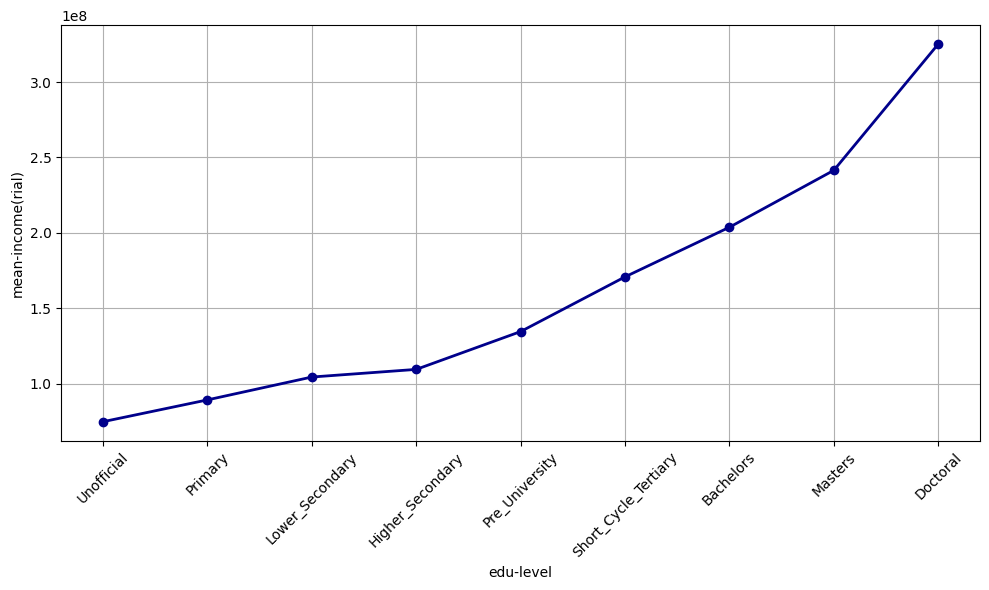

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

# لیست مرتب‌شده سطح تحصیلات
valid_levels = [
    "Unofficial",             
    "Primary",                
    "Lower_Secondary",        
    "Higher_Secondary",       
    "Pre_University",         
    "Short_Cycle_Tertiary",   
    "Bachelors",              
    "Masters",                
    "Doctoral"                
]

# فیلتر فقط سرپرست‌ها با سطح تحصیلات معتبر
df_1395 = members_1395[(members_1395["Member_Number"] == 1) & (members_1395["Education_Level"].isin(valid_levels))].copy()

# تبدیل به نوع مرتب Categorical
df_1395["Education_Level"] = pd.Categorical(df_1395["Education_Level"], categories=valid_levels, ordered=True)

# اضافه کردن درآمد سرپرست‌ها از hhinc
df_1395 = df_1395.merge(
    hhinc_1395[hhinc_1395["Member_Number"] == 1][["ID", "Annual_Continuous_Income"]],
    on="ID",
    how="left"
)
print(df_1395["Annual_Continuous_Income"].isna().sum())
print((df_1395["Annual_Continuous_Income"] == 0).sum())

print(df_1395.shape)

# حذف ردیف‌هایی که درآمد ندارن
df_1395 = df_1395.dropna(subset=["Annual_Continuous_Income"])
print((df_1395["Annual_Continuous_Income"] == 0).sum())

print(df_1395.shape)

# محاسبه میانگین درآمد برای هر سطح تحصیل
mean_income_1395 = df_1395.groupby("Education_Level")["Annual_Continuous_Income"].mean().reindex(valid_levels)

# 📈 رسم نمودار
plt.figure(figsize=(10, 6))
plt.plot(mean_income_1395.index, mean_income_1395.values, marker='o', color='darkblue', linewidth=2)
plt.xlabel("edu-level")
plt.ylabel("mean-income(rial)")
plt.title("")
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Alternative aggregation by household head


missing incomes: 14242 / 27483
Education_Level
Unofficial              7.809027e+07
Primary                 9.294129e+07
Lower_Secondary         1.084312e+08
Higher_Secondary        1.120307e+08
Pre_University          1.378395e+08
Short_Cycle_Tertiary    1.765099e+08
Bachelors               2.063468e+08
Masters                 2.528615e+08
Doctoral                3.819727e+08
Name: Head_Income, dtype: float64


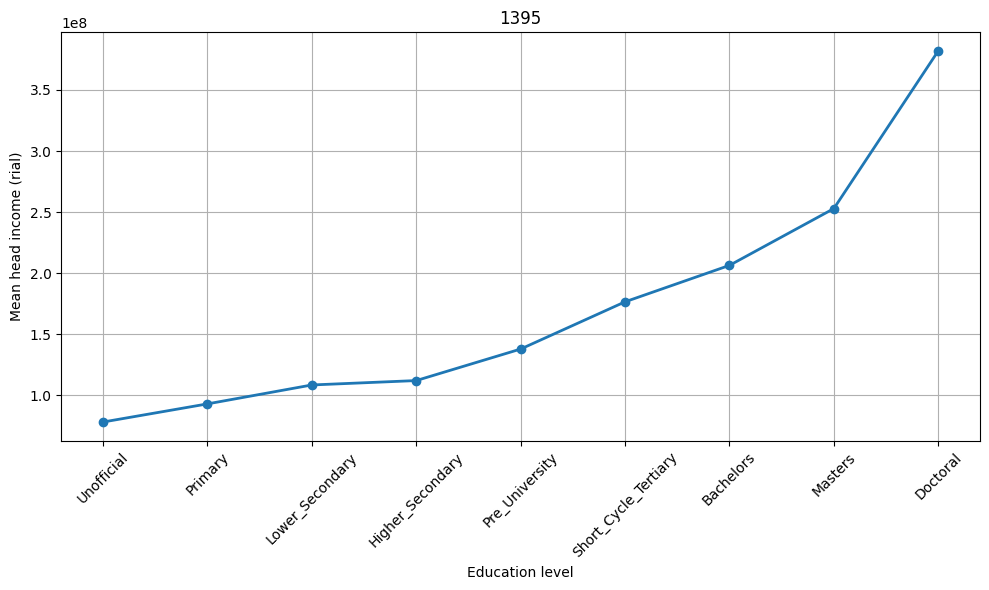

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

valid_levels = [
    "Unofficial","Primary","Lower_Secondary","Higher_Secondary",
    "Pre_University","Short_Cycle_Tertiary","Bachelors","Masters","Doctoral"
]

# 1) فقط سرپرست‌ها + ترتیب تحصیلات
heads = members_1395.loc[members_1395["Member_Number"] == 1, ["ID","Education_Level"]].copy()
heads = heads[heads["Education_Level"].isin(valid_levels)]
heads["Education_Level"] = pd.Categorical(heads["Education_Level"], categories=valid_levels, ordered=True)

# 2) درآمد سرپرست از جدول درآمد اعضا
inc = hhinc_1395.copy()

# تشخیص نام ستون درآمد
if "Income" in inc.columns:
    income_col = "Income"
elif "Annual_Continuous_Income" in inc.columns:
    income_col = "Annual_Continuous_Income"
else:
    raise ValueError("ستون درآمد در hhinc_1395 پیدا نشد (Income یا Annual_Continuous_Income).")

# اگر ستون Member_Number در جدول درآمد موجود است، سرپرست‌ها را جدا کن؛
# اگر نیست، فرض می‌کنیم درآمد عضو-سطحی نیست و مستقیم جمع خانواهی/سرپرست است.
if "Member_Number" in inc.columns:
    inc_head = inc.loc[inc["Member_Number"] == 1, ["ID", income_col]].copy()
else:
    inc_head = inc[["ID", income_col]].copy()

# ممکن است برای یک ID بیش از یک ردیف باشد → جمع بزنیم
inc_head = inc_head.groupby("ID", as_index=False)[income_col].sum().rename(columns={income_col: "Head_Income"})

# 3) merge
df_1395 = heads.merge(inc_head, on="ID", how="left")

# چک سلامت
print("missing incomes:", df_1395["Head_Income"].isna().sum(), "/", len(df_1395))

# حذف رکوردهای بدون درآمد (یا می‌تونی نگه داری و صفر کنی، بسته به هدف)
df_1395 = df_1395.dropna(subset=["Head_Income"])

# 4) میانگین درآمد بر حسب سطح تحصیلات
mean_income_1395 = (df_1395
    .groupby("Education_Level", observed=True)["Head_Income"]
    .mean()
    .reindex(valid_levels))

print(mean_income_1395)

# 5) رسم
if mean_income_1395.notna().sum() == 0:
    print("هیچ مقدار معتبری برای رسم ندارم (همه NaN شدند). نام ستون‌ها/merge را چک کن.")
else:
    plt.figure(figsize=(10,6))
    plt.plot([str(x) for x in mean_income_1395.index], mean_income_1395.values,
             marker="o", linewidth=2)
    plt.xlabel("Education level")
    plt.ylabel("Mean head income (rial)")
    plt.title("1395")
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


## Urban-rural income models



---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.251
Model:                                  OLS   Adj. R-squared:                  0.251
Method:                       Least Squares   F-statistic:                     2294.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:45:02   Log-Likelihood:            -2.6759e+05
No. Observations:                     13698   AIC:                         5.352e+05
Df Residuals:                         13695   BIC:                         5.352e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------

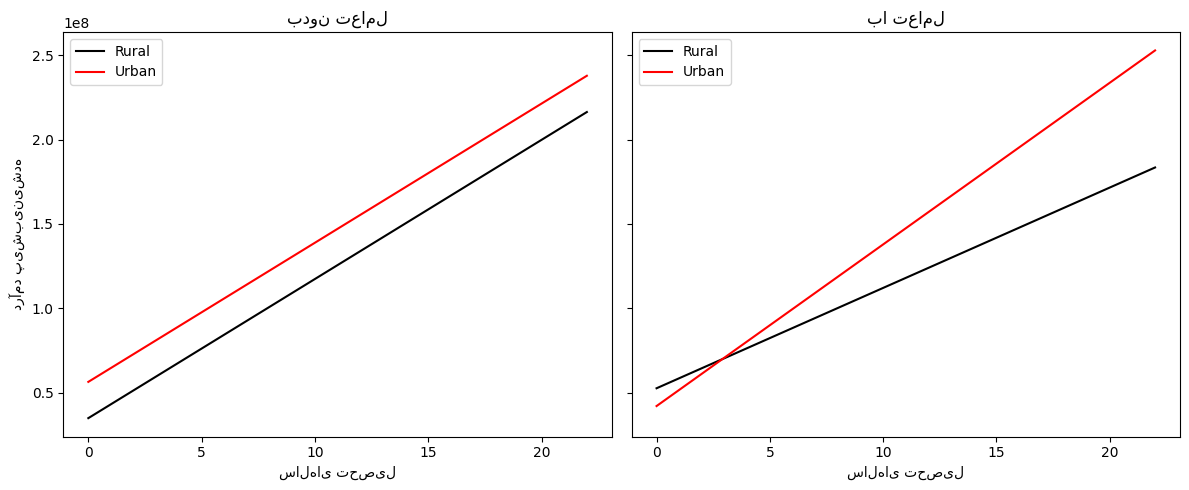

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# ----------------------
# 1. نگاشت سطح تحصیلات به سال تحصیل
# ----------------------
edu_map = {
    "Unofficial": 0,
    "Primary": 5,
    "Lower_Secondary": 8,
    "Higher_Secondary": 12,
    "Pre_University": 13,
    "Short_Cycle_Tertiary": 14,
    "Bachelors": 16,
    "Masters": 18,
    "Doctoral": 22
}

# فیلتر فقط سرپرست‌ها با سطح تحصیلات معتبر
df = members_1395[(members_1395["Member_Number"] == 1) & 
             (members_1395["Education_Level"].isin(valid_levels))].copy()

# افزودن سال تحصیل
# افزودن سال تحصیل و تبدیل به عدد
df["Years_Edu"] = df["Education_Level"].map(edu_map).astype(float)


# اضافه کردن درآمد
df = df.merge(
    hhinc_1395[hhinc_1395["Member_Number"] == 1][["ID", "Annual_Continuous_Income"]],
    on="ID", how="left"
)

# اضافه کردن شهری/روستایی
urban_rural = table_1395[["ID", "Urban_Rural"]].drop_duplicates()
df = df.merge(urban_rural, on="ID", how="left")

# حذف ردیف‌هایی که درآمد ندارند
df = df.dropna(subset=["Annual_Continuous_Income"])

# تبدیل Urban_Rural به ۰ و ۱
df["Urban"] = df["Urban_Rural"].apply(lambda x: 1 if str(x).lower() == "urban" else 0)

# ----------------------
# 2. مدل‌سازی
# ----------------------
# مدل بدون تعامل
model_no_inter = smf.ols("Annual_Continuous_Income ~ Years_Edu + Urban", data=df).fit()

# مدل با تعامل
model_inter = smf.ols("Annual_Continuous_Income ~ Years_Edu * Urban", data=df).fit()

print("\n---- مدل بدون تعامل ----")
print(model_no_inter.summary())

print("\n---- مدل با تعامل ----")
print(model_inter.summary())

# ----------------------
# 3. رسم نمودار
# ----------------------
# بازه تحصیلات برای پیش‌بینی
years_range = np.linspace(df["Years_Edu"].min(), df["Years_Edu"].max(), 100)

plot_df = pd.DataFrame({
    "Years_Edu": np.tile(years_range, 2),
    "Urban": np.repeat([0, 1], len(years_range))
})

# پیش‌بینی
plot_df["pred_no_inter"] = model_no_inter.predict(plot_df)
plot_df["pred_inter"] = model_inter.predict(plot_df)

# رسم
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# بدون تعامل
for u, color, label in [(0, "black", "Rural"), (1, "red", "Urban")]:
    subset = plot_df[plot_df["Urban"] == u]
    axes[0].plot(subset["Years_Edu"], subset["pred_no_inter"], color=color, label=label)

axes[0].set_title("بدون تعامل")
axes[0].set_xlabel("سال‌های تحصیل")
axes[0].set_ylabel("درآمد پیش‌بینی‌شده")
axes[0].legend()

# با تعامل
for u, color, label in [(0, "black", "Rural"), (1, "red", "Urban")]:
    subset = plot_df[plot_df["Urban"] == u]
    axes[1].plot(subset["Years_Edu"], subset["pred_inter"], color=color, label=label)

axes[1].set_title("با تعامل")
axes[1].set_xlabel("سال‌های تحصیل")
axes[1].legend()

plt.tight_layout()
plt.show()


## Recorded data-library version


In [6]:
import hbsir
print(hbsir.__version__)


0.6.3


## Urban-rural models across years



=== پردازش سال 1393 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.210
Model:                                  OLS   Adj. R-squared:                  0.210
Method:                       Least Squares   F-statistic:                     1866.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:45:12   Log-Likelihood:            -2.6975e+05
No. Observations:                     14027   AIC:                         5.395e+05
Df Residuals:                         14024   BIC:                         5.395e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------

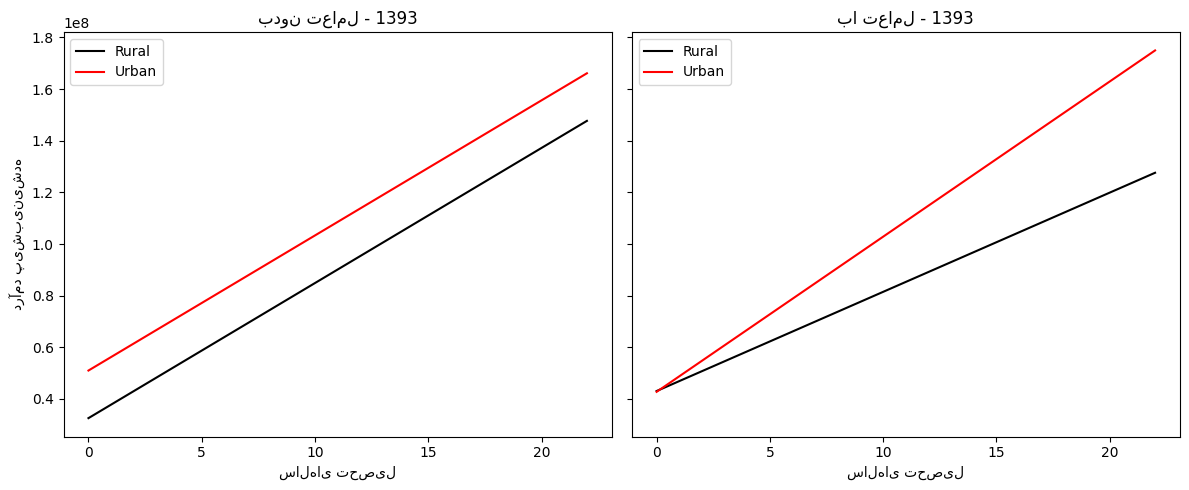


=== پردازش سال 1394 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.241
Model:                                  OLS   Adj. R-squared:                  0.240
Method:                       Least Squares   F-statistic:                     2199.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:45:22   Log-Likelihood:            -2.6857e+05
No. Observations:                     13888   AIC:                         5.371e+05
Df Residuals:                         13885   BIC:                         5.372e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------

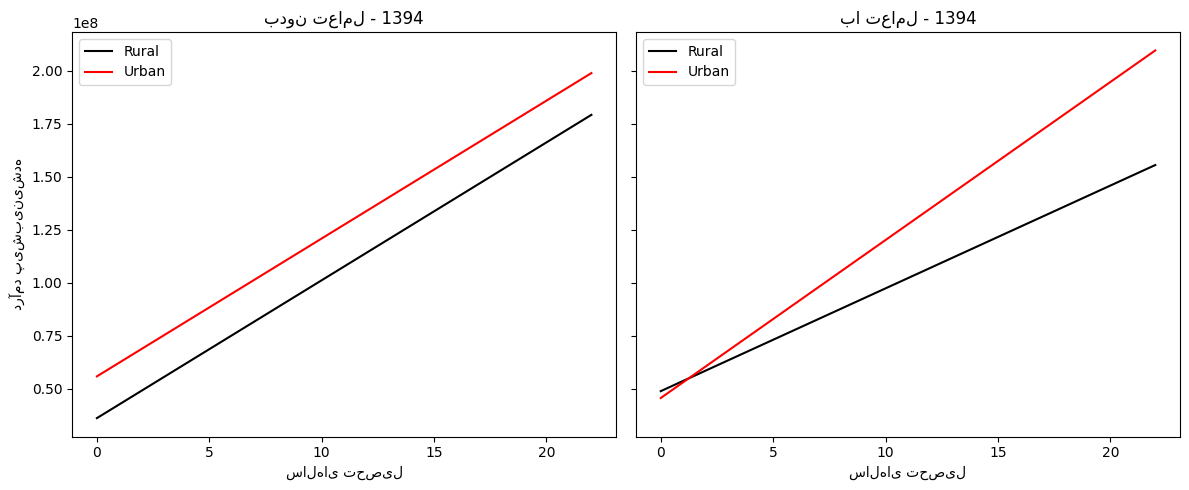


=== پردازش سال 1395 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.251
Model:                                  OLS   Adj. R-squared:                  0.251
Method:                       Least Squares   F-statistic:                     2294.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:45:31   Log-Likelihood:            -2.6759e+05
No. Observations:                     13698   AIC:                         5.352e+05
Df Residuals:                         13695   BIC:                         5.352e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------

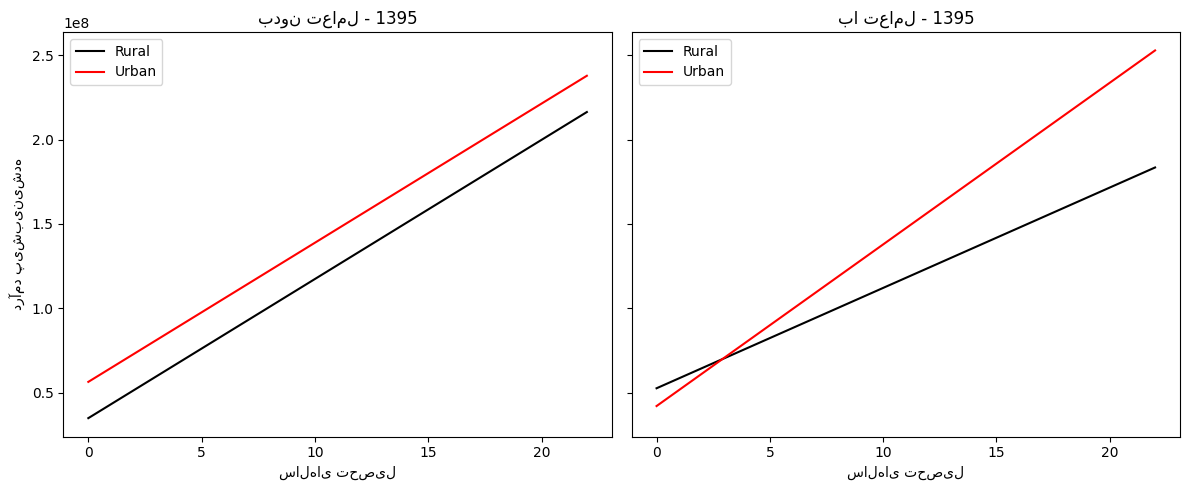


=== پردازش سال 1396 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.275
Model:                                  OLS   Adj. R-squared:                  0.275
Method:                       Least Squares   F-statistic:                     2575.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:45:45   Log-Likelihood:            -2.6686e+05
No. Observations:                     13552   AIC:                         5.337e+05
Df Residuals:                         13549   BIC:                         5.337e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------

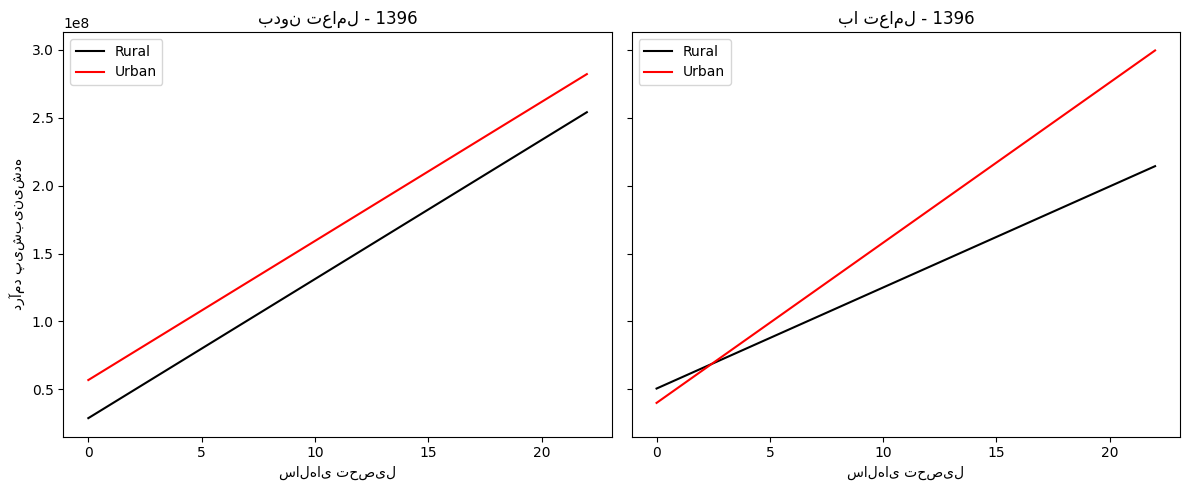


=== پردازش سال 1397 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.242
Model:                                  OLS   Adj. R-squared:                  0.242
Method:                       Least Squares   F-statistic:                     2356.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:45:53   Log-Likelihood:            -2.9378e+05
No. Observations:                     14773   AIC:                         5.876e+05
Df Residuals:                         14770   BIC:                         5.876e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------

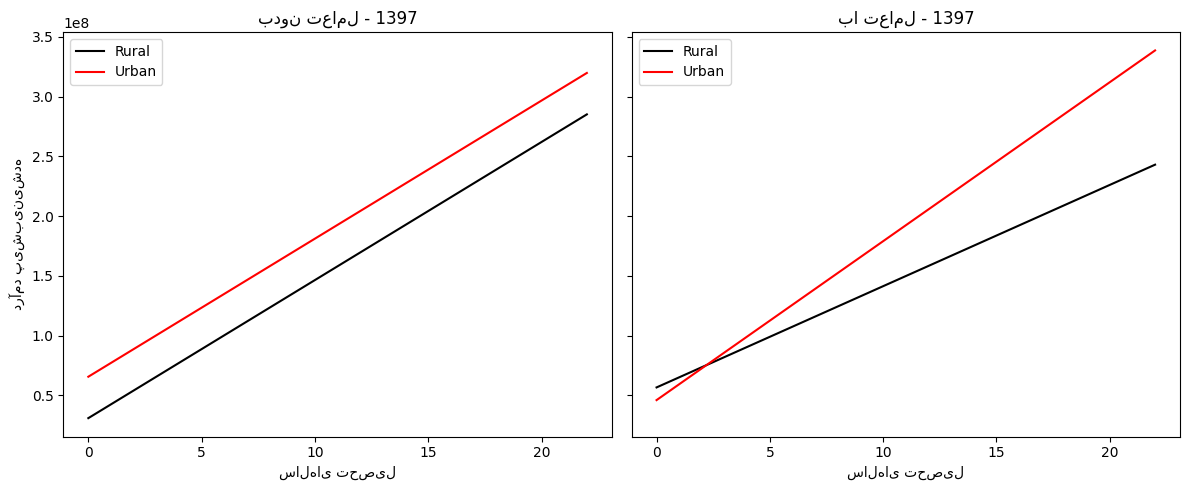


=== پردازش سال 1398 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.247
Model:                                  OLS   Adj. R-squared:                  0.246
Method:                       Least Squares   F-statistic:                     2306.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:46:03   Log-Likelihood:            -2.8322e+05
No. Observations:                     14098   AIC:                         5.664e+05
Df Residuals:                         14095   BIC:                         5.665e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------

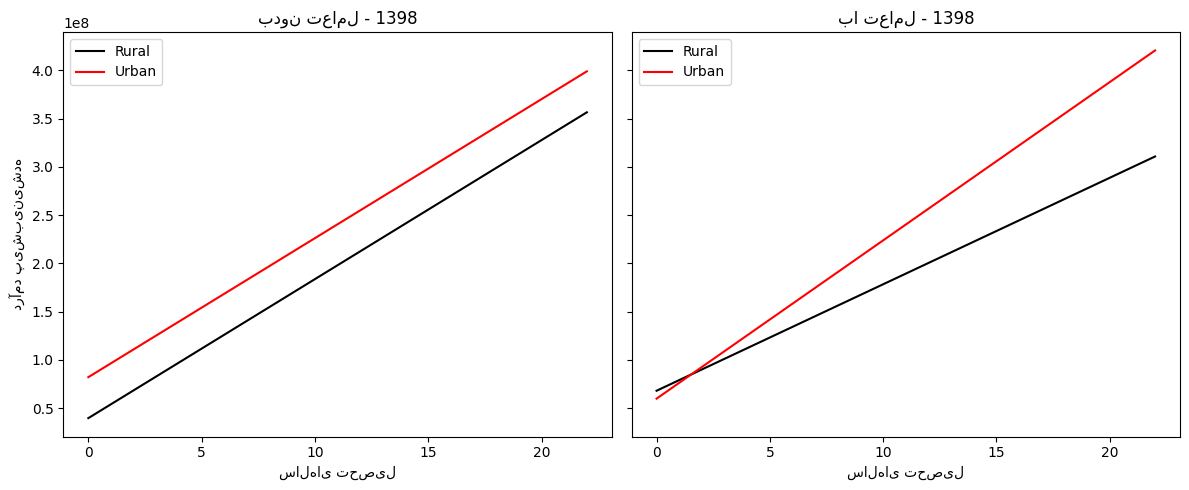


=== پردازش سال 1399 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.241
Model:                                  OLS   Adj. R-squared:                  0.241
Method:                       Least Squares   F-statistic:                     2273.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:46:13   Log-Likelihood:            -2.9233e+05
No. Observations:                     14340   AIC:                         5.847e+05
Df Residuals:                         14337   BIC:                         5.847e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------

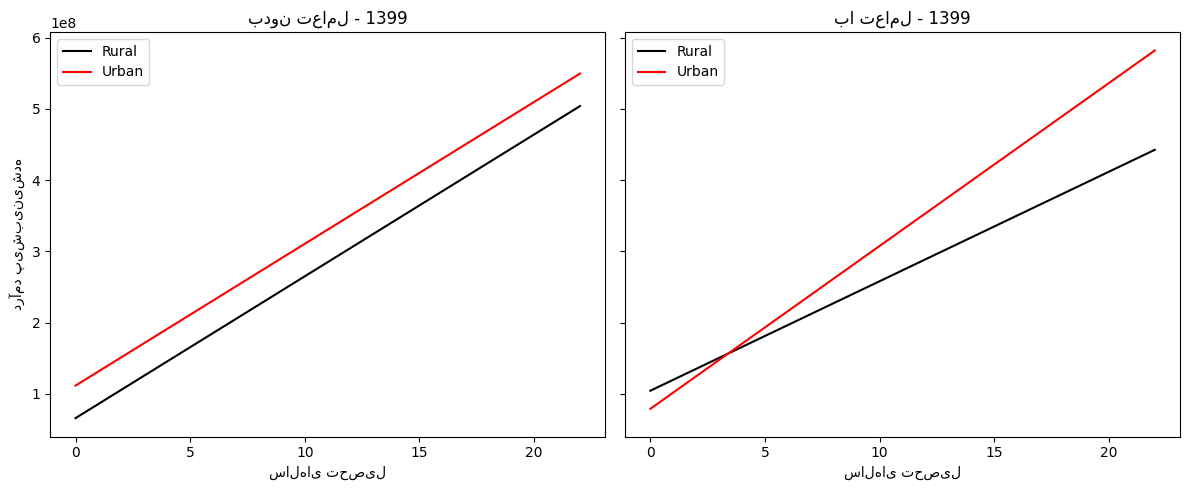


=== پردازش سال 1400 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.214
Model:                                  OLS   Adj. R-squared:                  0.214
Method:                       Least Squares   F-statistic:                     1947.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:46:22   Log-Likelihood:            -2.9751e+05
No. Observations:                     14308   AIC:                         5.950e+05
Df Residuals:                         14305   BIC:                         5.951e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------

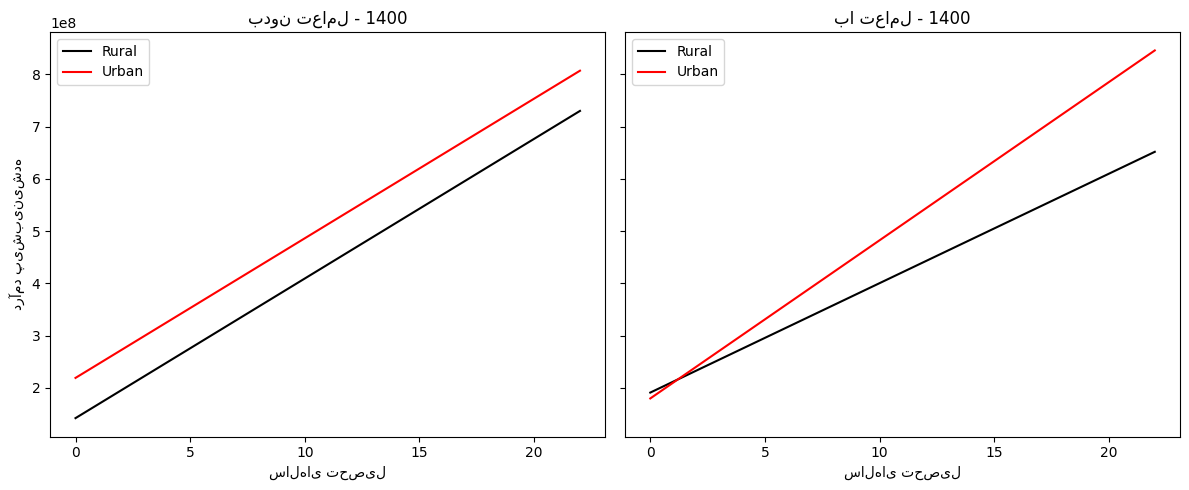


=== پردازش سال 1401 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.171
Model:                                  OLS   Adj. R-squared:                  0.171
Method:                       Least Squares   F-statistic:                     1436.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:46:32   Log-Likelihood:            -2.9557e+05
No. Observations:                     13946   AIC:                         5.911e+05
Df Residuals:                         13943   BIC:                         5.912e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------

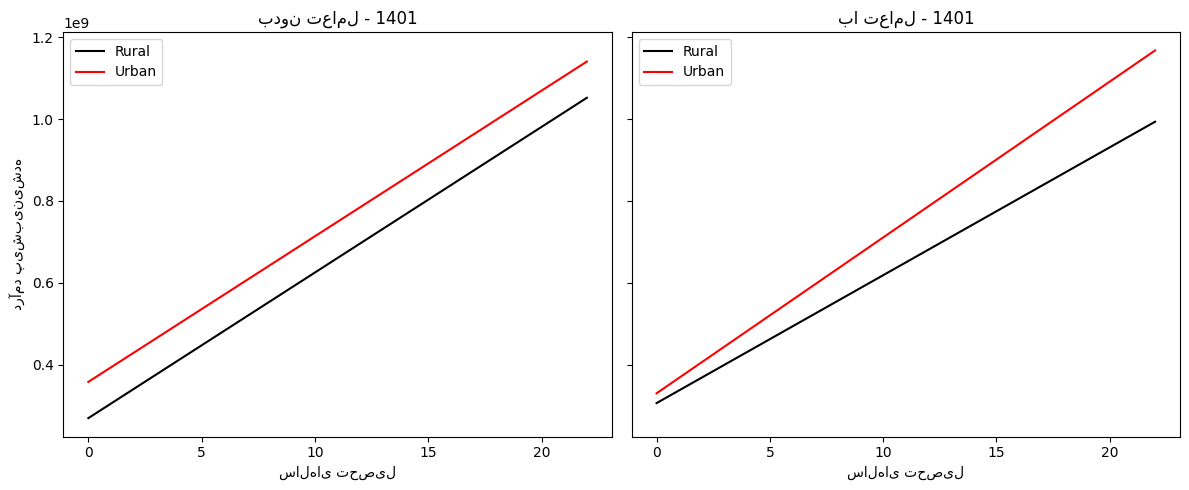


=== پردازش سال 1402 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.164
Model:                                  OLS   Adj. R-squared:                  0.164
Method:                       Least Squares   F-statistic:                     1307.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:46:43   Log-Likelihood:            -2.8822e+05
No. Observations:                     13359   AIC:                         5.764e+05
Df Residuals:                         13356   BIC:                         5.765e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------

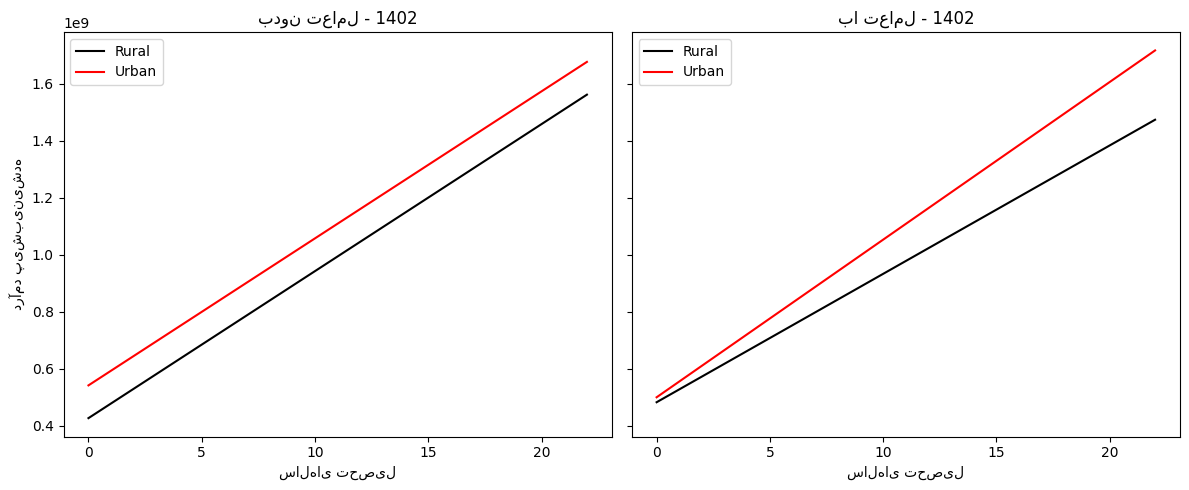


=== پردازش سال 1403 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.159
Model:                                  OLS   Adj. R-squared:                  0.159
Method:                       Least Squares   F-statistic:                     1229.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:46:55   Log-Likelihood:            -2.8382e+05
No. Observations:                     13031   AIC:                         5.677e+05
Df Residuals:                         13028   BIC:                         5.677e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------

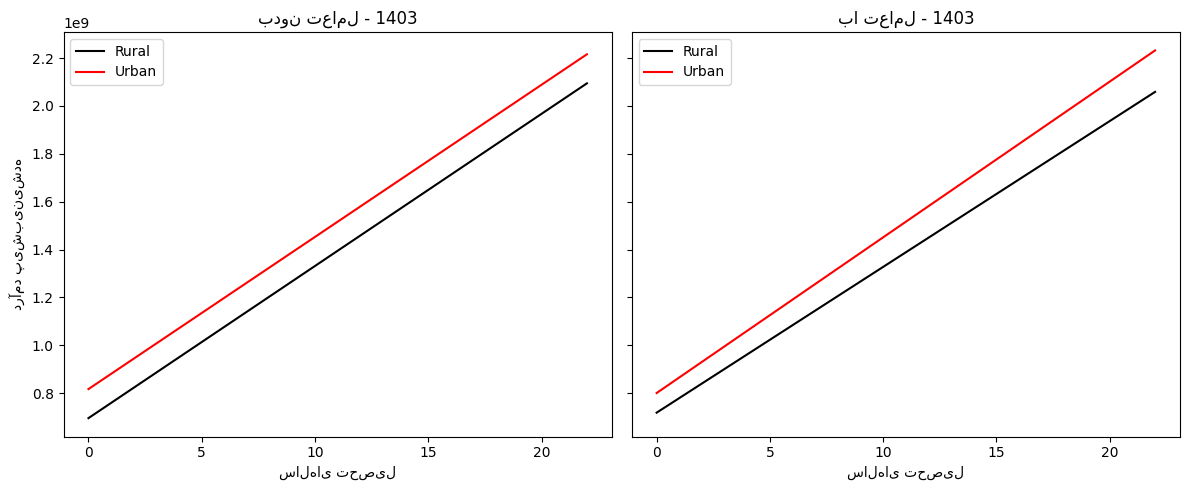

In [7]:
for year in range(1393, 1404):
    print(f"\n=== پردازش سال {year} ===")
    try:
        # ---------- بارگذاری داده‌ها ----------
        hbsir.setup(method="download_cleaned",download_source="mirror",years=[year])
        table = hbsir.load_table("Expenditures", years=[year])
        table = hbsir.add_attribute(table, name="Province")
        table = hbsir.add_attribute(table, name="County")
        table = hbsir.add_attribute(table, name="Urban_Rural")

        hhinc = hbsir.load_table("employment_income", years=[year])
        members = hbsir.load_table("members_properties", years=[year])

        # ---------- پردازش ----------
        df = members[(members["Member_Number"] == 1) & 
                     (members["Education_Level"].isin(valid_levels))].copy()
        df["Years_Edu"] = df["Education_Level"].map(edu_map).astype(float)

        df = df.merge(
            hhinc[hhinc["Member_Number"] == 1][["ID", "Annual_Continuous_Income"]],
            on="ID", how="left"
        )

        urban_rural = table[["ID", "Urban_Rural"]].drop_duplicates()
        df = df.merge(urban_rural, on="ID", how="left")

        df = df.dropna(subset=["Annual_Continuous_Income"])
        df["Urban"] = df["Urban_Rural"].apply(lambda x: 1 if str(x).lower() == "urban" else 0)

        # ---------- مدل ----------
        model_no_inter = smf.ols("Annual_Continuous_Income ~ Years_Edu + Urban", data=df).fit()
        model_inter = smf.ols("Annual_Continuous_Income ~ Years_Edu * Urban", data=df).fit()

        print("\n---- مدل بدون تعامل ----")
        print(model_no_inter.summary())

        print("\n---- مدل با تعامل ----")
        print(model_inter.summary())

        # ---------- نمودار ----------
        years_range = np.linspace(df["Years_Edu"].min(), df["Years_Edu"].max(), 100)
        plot_df = pd.DataFrame({
            "Years_Edu": np.tile(years_range, 2),
            "Urban": np.repeat([0, 1], len(years_range))
        })
        plot_df["pred_no_inter"] = model_no_inter.predict(plot_df)
        plot_df["pred_inter"] = model_inter.predict(plot_df)

        fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
        for u, color, label in [(0, "black", "Rural"), (1, "red", "Urban")]:
            subset = plot_df[plot_df["Urban"] == u]
            axes[0].plot(subset["Years_Edu"], subset["pred_no_inter"], color=color, label=label)
            axes[1].plot(subset["Years_Edu"], subset["pred_inter"], color=color, label=label)

        axes[0].set_title(f"بدون تعامل - {year}")
        axes[0].set_xlabel("سال‌های تحصیل")
        axes[0].set_ylabel("درآمد پیش‌بینی‌شده")
        axes[0].legend()

        axes[1].set_title(f"با تعامل - {year}")
        axes[1].set_xlabel("سال‌های تحصیل")
        axes[1].legend()

        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"⚠ خطا در پردازش سال {year}: {e}")
        continue


## Observed incomes and fitted lines



=== پردازش سال 1396 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.275
Model:                                  OLS   Adj. R-squared:                  0.275
Method:                       Least Squares   F-statistic:                     2575.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:47:04   Log-Likelihood:            -2.6686e+05
No. Observations:                     13552   AIC:                         5.337e+05
Df Residuals:                         13549   BIC:                         5.337e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------

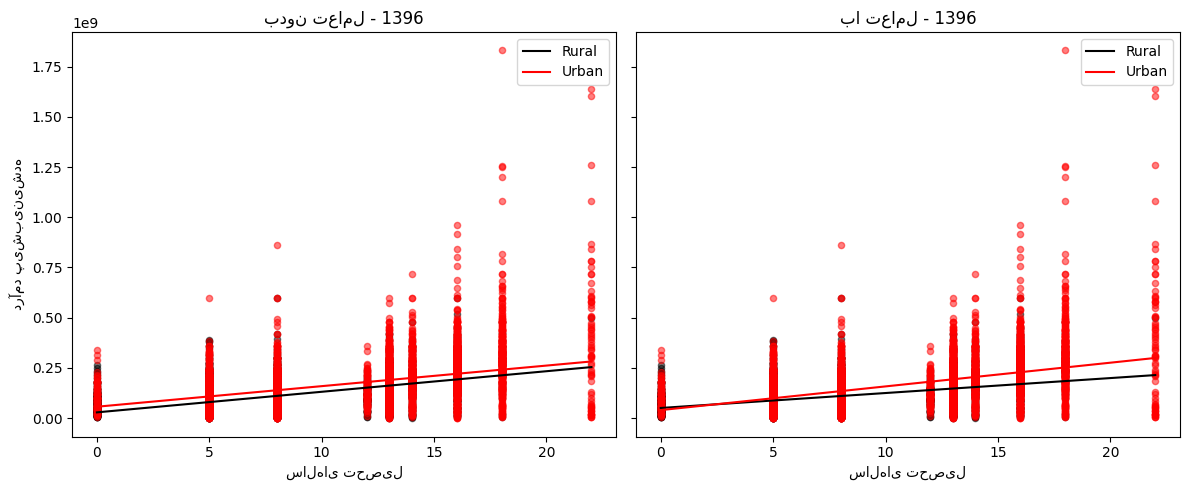


=== پردازش سال 1397 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.242
Model:                                  OLS   Adj. R-squared:                  0.242
Method:                       Least Squares   F-statistic:                     2356.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:47:13   Log-Likelihood:            -2.9378e+05
No. Observations:                     14773   AIC:                         5.876e+05
Df Residuals:                         14770   BIC:                         5.876e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------

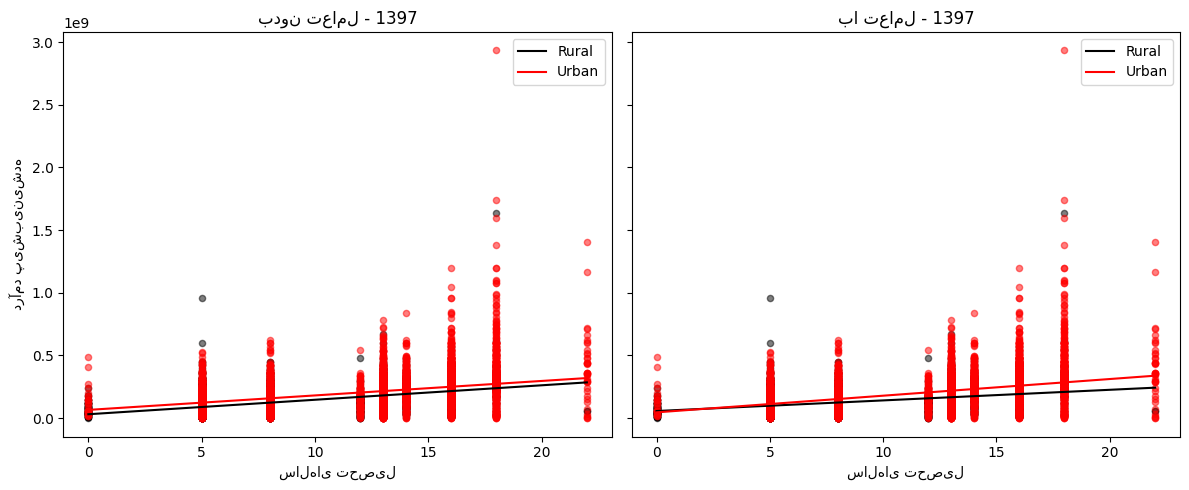


=== پردازش سال 1398 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.247
Model:                                  OLS   Adj. R-squared:                  0.246
Method:                       Least Squares   F-statistic:                     2306.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:47:22   Log-Likelihood:            -2.8322e+05
No. Observations:                     14098   AIC:                         5.664e+05
Df Residuals:                         14095   BIC:                         5.665e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------

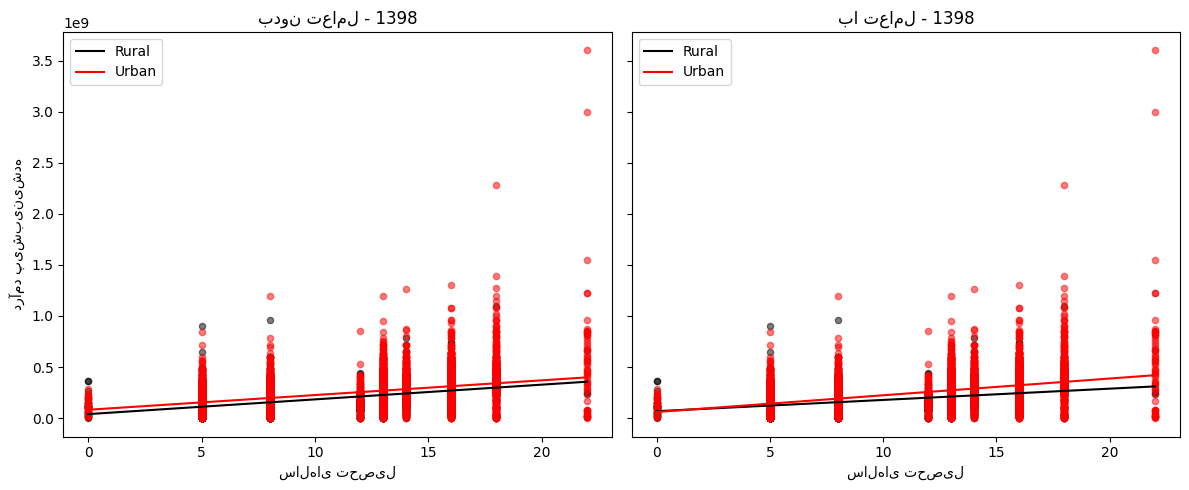


=== پردازش سال 1399 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.241
Model:                                  OLS   Adj. R-squared:                  0.241
Method:                       Least Squares   F-statistic:                     2273.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:47:30   Log-Likelihood:            -2.9233e+05
No. Observations:                     14340   AIC:                         5.847e+05
Df Residuals:                         14337   BIC:                         5.847e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------

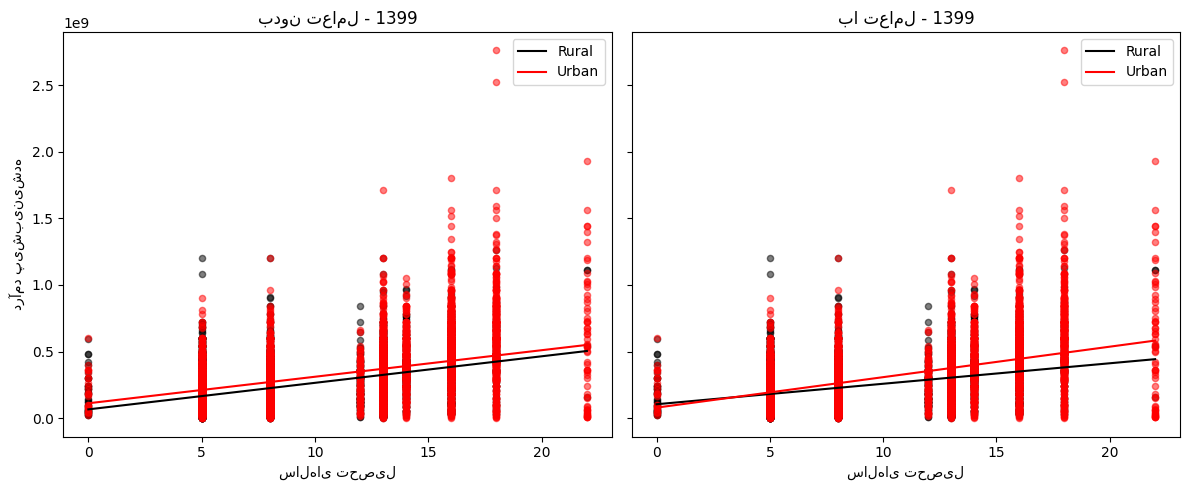


=== پردازش سال 1400 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.214
Model:                                  OLS   Adj. R-squared:                  0.214
Method:                       Least Squares   F-statistic:                     1947.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:47:37   Log-Likelihood:            -2.9751e+05
No. Observations:                     14308   AIC:                         5.950e+05
Df Residuals:                         14305   BIC:                         5.951e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------

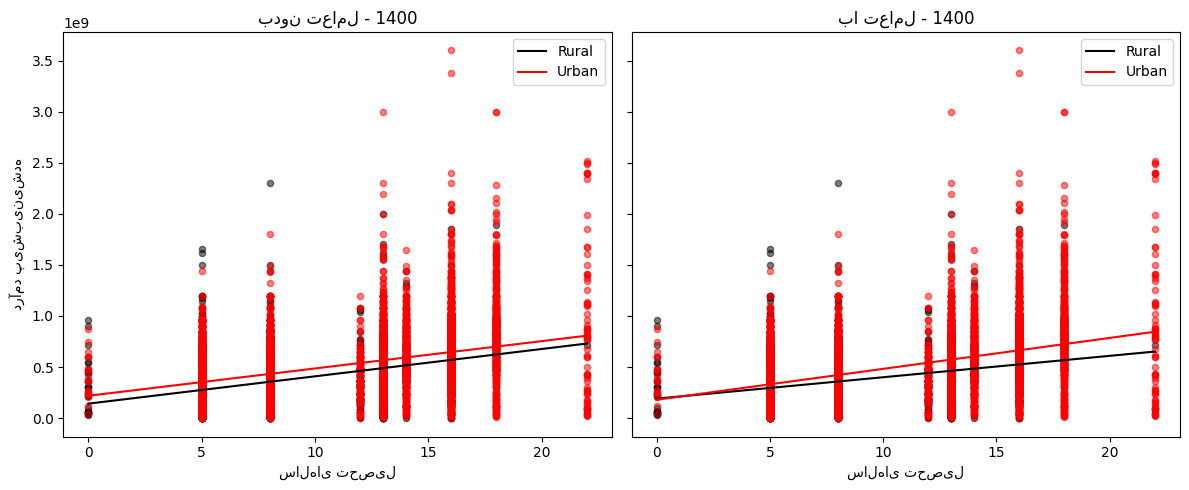


=== پردازش سال 1401 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.171
Model:                                  OLS   Adj. R-squared:                  0.171
Method:                       Least Squares   F-statistic:                     1436.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:47:46   Log-Likelihood:            -2.9557e+05
No. Observations:                     13946   AIC:                         5.911e+05
Df Residuals:                         13943   BIC:                         5.912e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------

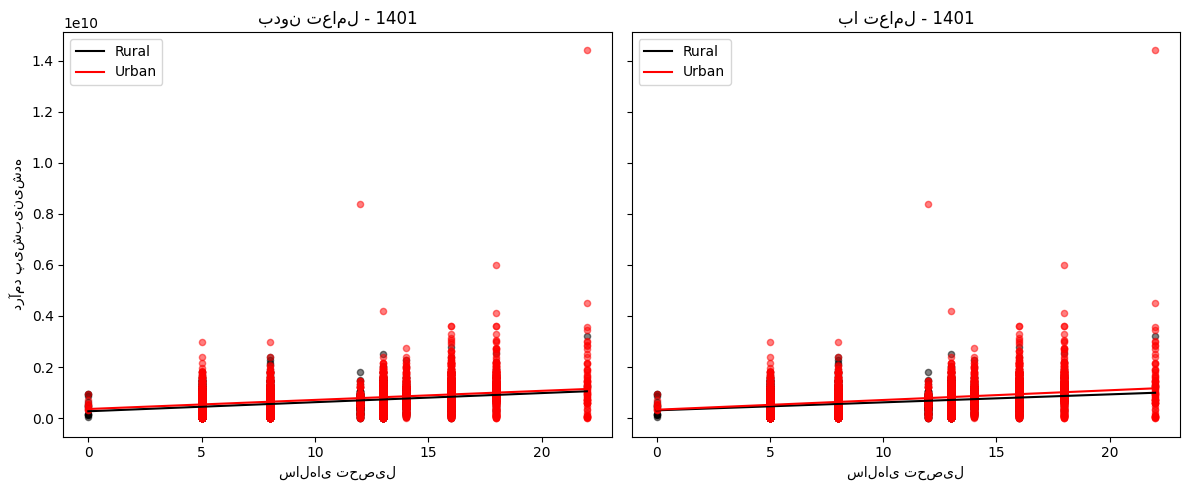

In [8]:
import hbsir
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

valid_levels = [
    "Unofficial", "Primary", "Lower_Secondary", "Higher_Secondary",
    "Pre_University", "Short_Cycle_Tertiary", "Bachelors", "Masters", "Doctoral"
]

edu_map = {
    "Unofficial": 0, "Primary": 5, "Lower_Secondary": 8, "Higher_Secondary": 12,
    "Pre_University": 13, "Short_Cycle_Tertiary": 14, "Bachelors": 16,
    "Masters": 18, "Doctoral": 22
}

for year in range(1396, 1402):
    print(f"\n=== پردازش سال {year} ===")
    try:
        # --- بارگذاری داده‌ها ---
        hbsir.setup(method="download_cleaned",download_source="mirror",years=[year])
        table = hbsir.load_table("Expenditures", years=[year])
        table = hbsir.add_attribute(table, name="Province")
        table = hbsir.add_attribute(table, name="County")
        table = hbsir.add_attribute(table, name="Urban_Rural")

        hhinc = hbsir.load_table("employment_income", years=[year])
        members = hbsir.load_table("members_properties", years=[year])

        # --- فیلتر سرپرست‌ها ---
        df = members[(members["Member_Number"] == 1) &
                     (members["Education_Level"].isin(valid_levels))].copy()
        df["Years_Edu"] = df["Education_Level"].map(edu_map).astype(float)

        # اضافه کردن درآمد
        df = df.merge(
            hhinc[hhinc["Member_Number"] == 1][["ID", "Annual_Continuous_Income"]],
            on="ID", how="left"
        )

        # اضافه کردن شهری/روستایی
        urban_rural = table[["ID", "Urban_Rural"]].drop_duplicates()
        df = df.merge(urban_rural, on="ID", how="left")

        # حذف ردیف‌های بدون درآمد
        df = df.dropna(subset=["Annual_Continuous_Income"])

        # تبدیل Urban_Rural به ۰ و ۱
        df["Urban"] = df["Urban_Rural"].apply(lambda x: 1 if str(x).lower() == "urban" else 0)

        # --- مدل‌سازی ---
        model_no_inter = smf.ols("Annual_Continuous_Income ~ Years_Edu + Urban", data=df).fit()
        model_inter = smf.ols("Annual_Continuous_Income ~ Years_Edu * Urban", data=df).fit()

        print("\n---- مدل بدون تعامل ----")
        print(model_no_inter.summary())

        print("\n---- مدل با تعامل ----")
        print(model_inter.summary())

        # --- داده‌های پیش‌بینی ---
        years_range = np.linspace(df["Years_Edu"].min(), df["Years_Edu"].max(), 100)
        plot_df = pd.DataFrame({
            "Years_Edu": np.tile(years_range, 2),
            "Urban": np.repeat([0, 1], len(years_range))
        })
        plot_df["pred_no_inter"] = model_no_inter.predict(plot_df)
        plot_df["pred_inter"] = model_inter.predict(plot_df)

        # --- رسم نمودار ---
        fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

        # بدون تعامل + نقاط واقعی
        for u, color, label in [(0, "black", "Rural"), (1, "red", "Urban")]:
            # خط رگرسیون
            subset_line = plot_df[plot_df["Urban"] == u]
            axes[0].plot(subset_line["Years_Edu"], subset_line["pred_no_inter"], color=color, label=label)

            # نقاط واقعی
            subset_points = df[df["Urban"] == u]
            axes[0].scatter(subset_points["Years_Edu"], subset_points["Annual_Continuous_Income"],
                            color=color, alpha=0.5, s=20)

        axes[0].set_title(f"بدون تعامل - {year}")
        axes[0].set_xlabel("سال‌های تحصیل")
        axes[0].set_ylabel("درآمد پیش‌بینی‌شده")
        axes[0].legend()

        # با تعامل + نقاط واقعی
        for u, color, label in [(0, "black", "Rural"), (1, "red", "Urban")]:
            subset_line = plot_df[plot_df["Urban"] == u]
            axes[1].plot(subset_line["Years_Edu"], subset_line["pred_inter"], color=color, label=label)

            subset_points = df[df["Urban"] == u]
            axes[1].scatter(subset_points["Years_Edu"], subset_points["Annual_Continuous_Income"],
                            color=color, alpha=0.5, s=20)

        axes[1].set_title(f"با تعامل - {year}")
        axes[1].set_xlabel("سال‌های تحصیل")
        axes[1].legend()

        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"⚠ خطا در پردازش سال {year}: {e}")
        continue


## Gender interaction models



=== پردازش سال 1393 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.192
Model:                                  OLS   Adj. R-squared:                  0.191
Method:                       Least Squares   F-statistic:                     1662.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:47:54   Log-Likelihood:            -2.6991e+05
No. Observations:                     14027   AIC:                         5.398e+05
Df Residuals:                         14024   BIC:                         5.399e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
------------

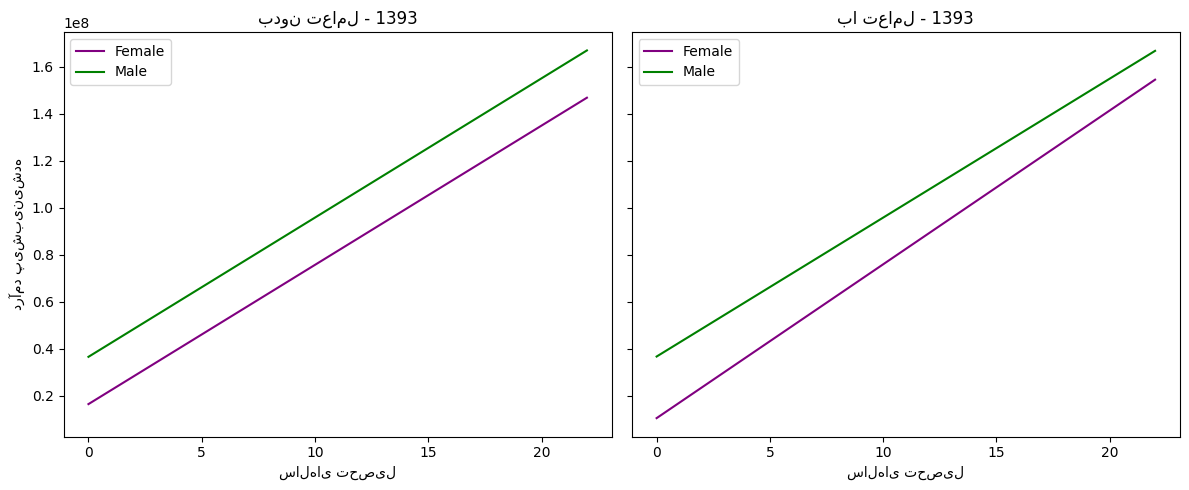


=== پردازش سال 1394 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.226
Model:                                  OLS   Adj. R-squared:                  0.226
Method:                       Least Squares   F-statistic:                     2025.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:48:02   Log-Likelihood:            -2.6870e+05
No. Observations:                     13888   AIC:                         5.374e+05
Df Residuals:                         13885   BIC:                         5.374e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
------------

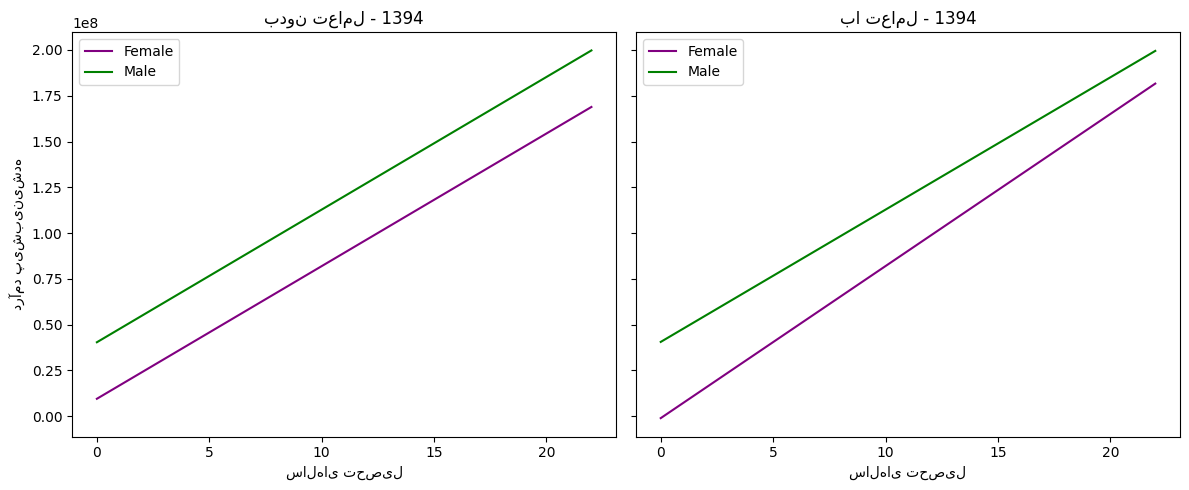


=== پردازش سال 1395 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.239
Model:                                  OLS   Adj. R-squared:                  0.239
Method:                       Least Squares   F-statistic:                     2154.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:48:10   Log-Likelihood:            -2.6769e+05
No. Observations:                     13698   AIC:                         5.354e+05
Df Residuals:                         13695   BIC:                         5.354e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
------------

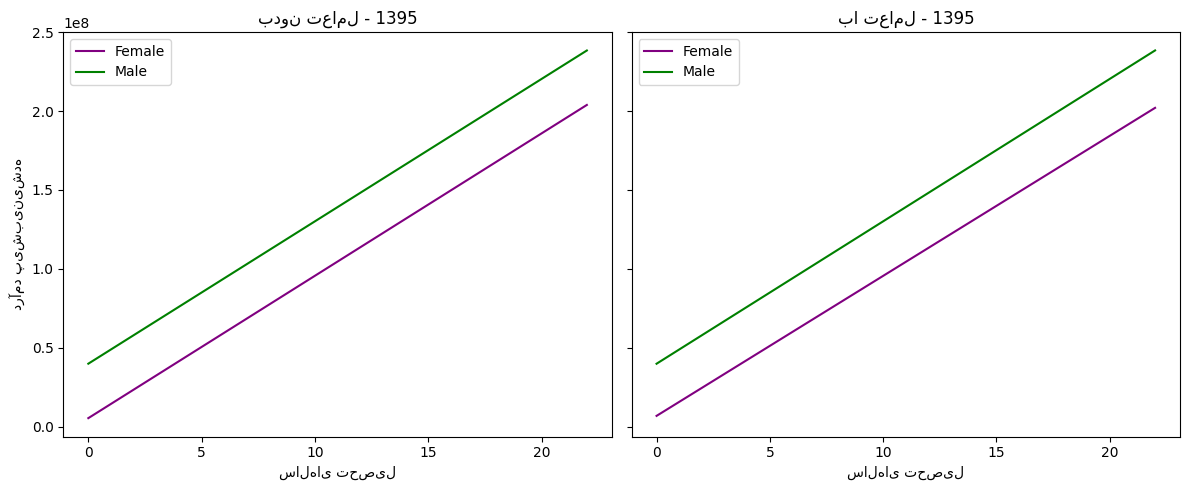


=== پردازش سال 1396 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.262
Model:                                  OLS   Adj. R-squared:                  0.262
Method:                       Least Squares   F-statistic:                     2403.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:48:16   Log-Likelihood:            -2.6698e+05
No. Observations:                     13552   AIC:                         5.340e+05
Df Residuals:                         13549   BIC:                         5.340e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
------------

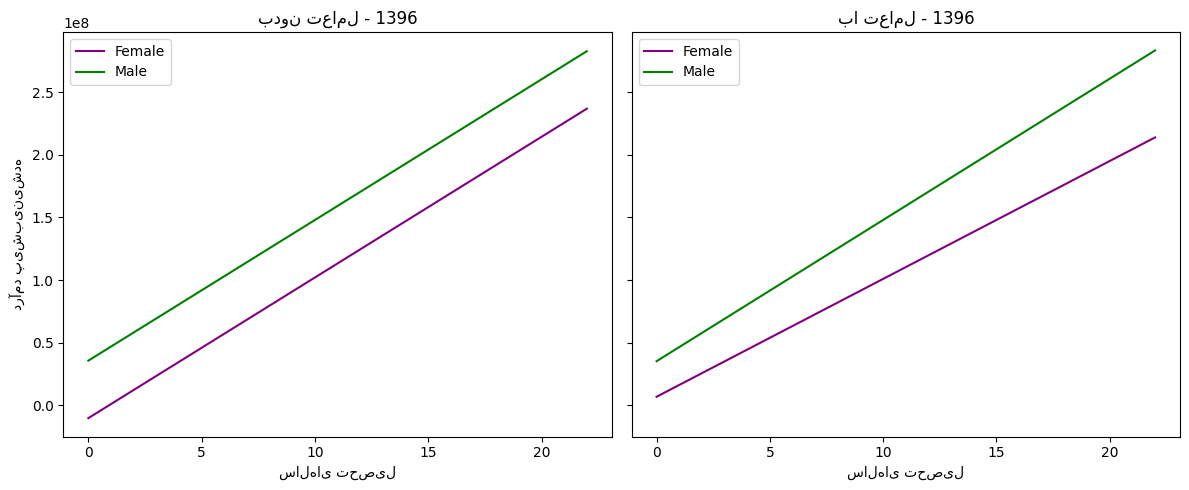


=== پردازش سال 1397 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.226
Model:                                  OLS   Adj. R-squared:                  0.226
Method:                       Least Squares   F-statistic:                     2157.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:48:24   Log-Likelihood:            -2.9393e+05
No. Observations:                     14773   AIC:                         5.879e+05
Df Residuals:                         14770   BIC:                         5.879e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
------------

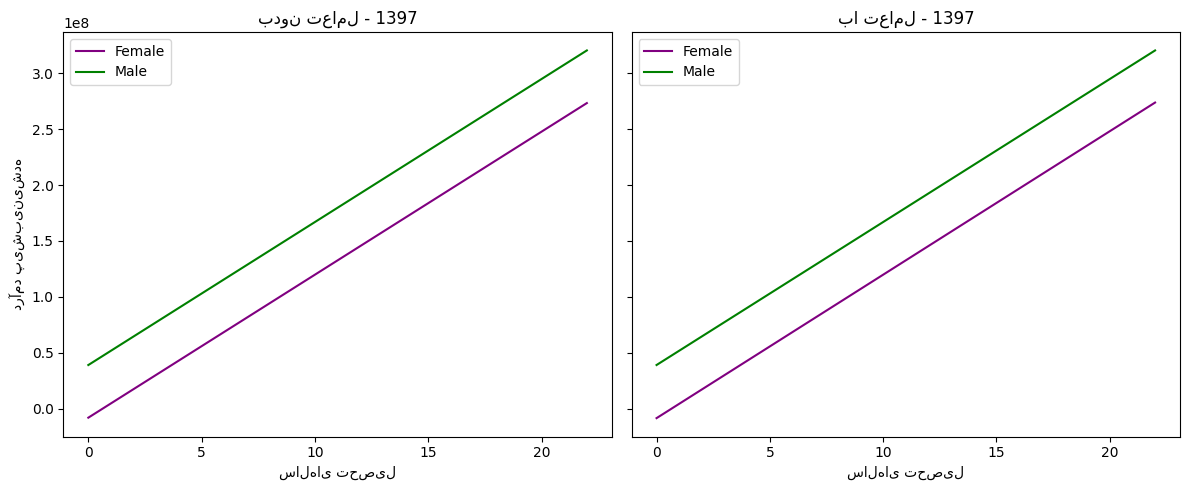


=== پردازش سال 1398 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.231
Model:                                  OLS   Adj. R-squared:                  0.231
Method:                       Least Squares   F-statistic:                     2115.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:48:30   Log-Likelihood:            -2.8336e+05
No. Observations:                     14098   AIC:                         5.667e+05
Df Residuals:                         14095   BIC:                         5.668e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
------------

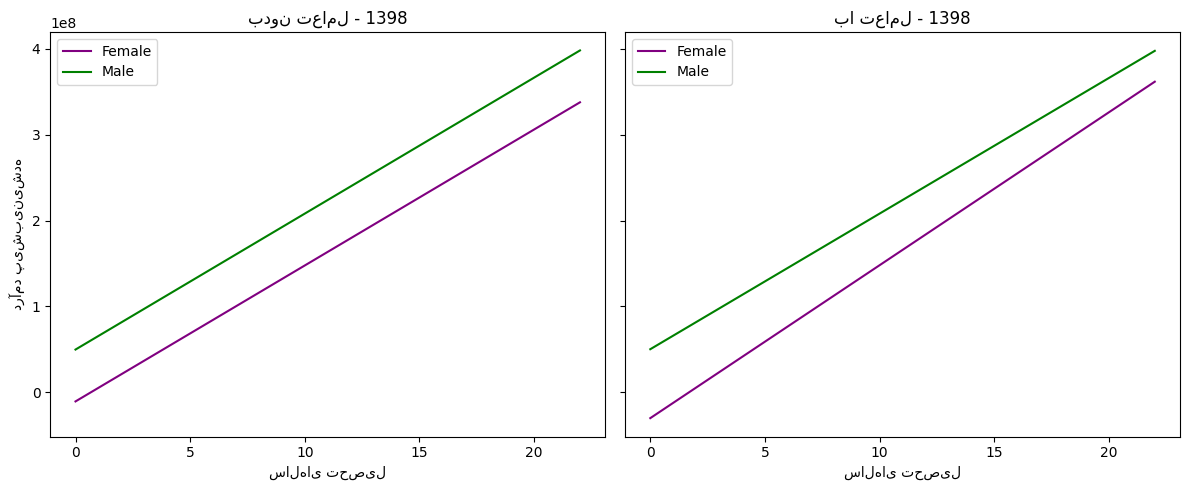


=== پردازش سال 1399 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.232
Model:                                  OLS   Adj. R-squared:                  0.232
Method:                       Least Squares   F-statistic:                     2163.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:48:36   Log-Likelihood:            -2.9241e+05
No. Observations:                     14340   AIC:                         5.848e+05
Df Residuals:                         14337   BIC:                         5.849e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
------------

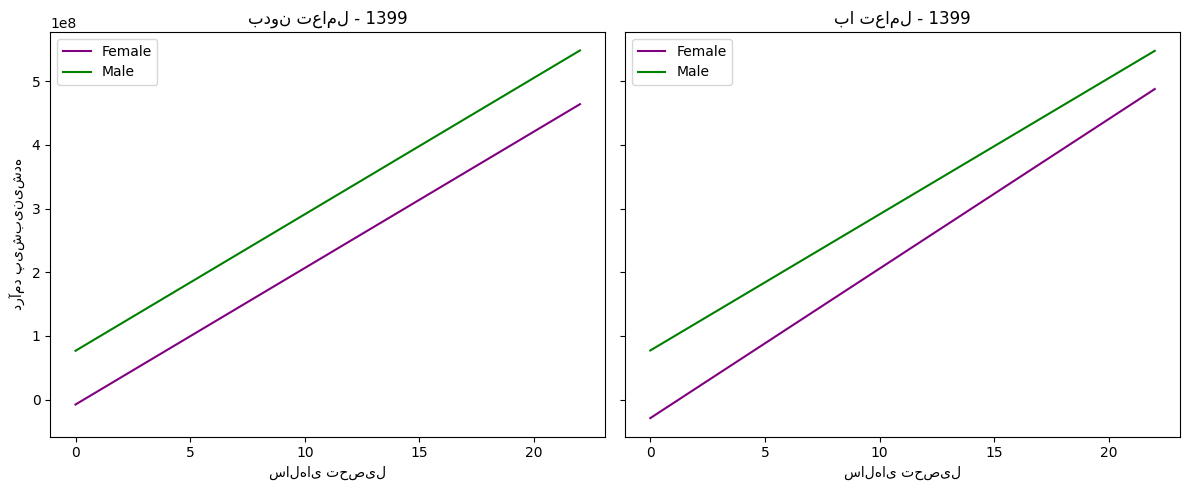


=== پردازش سال 1400 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.201
Model:                                  OLS   Adj. R-squared:                  0.201
Method:                       Least Squares   F-statistic:                     1803.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:48:44   Log-Likelihood:            -2.9763e+05
No. Observations:                     14308   AIC:                         5.953e+05
Df Residuals:                         14305   BIC:                         5.953e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
------------

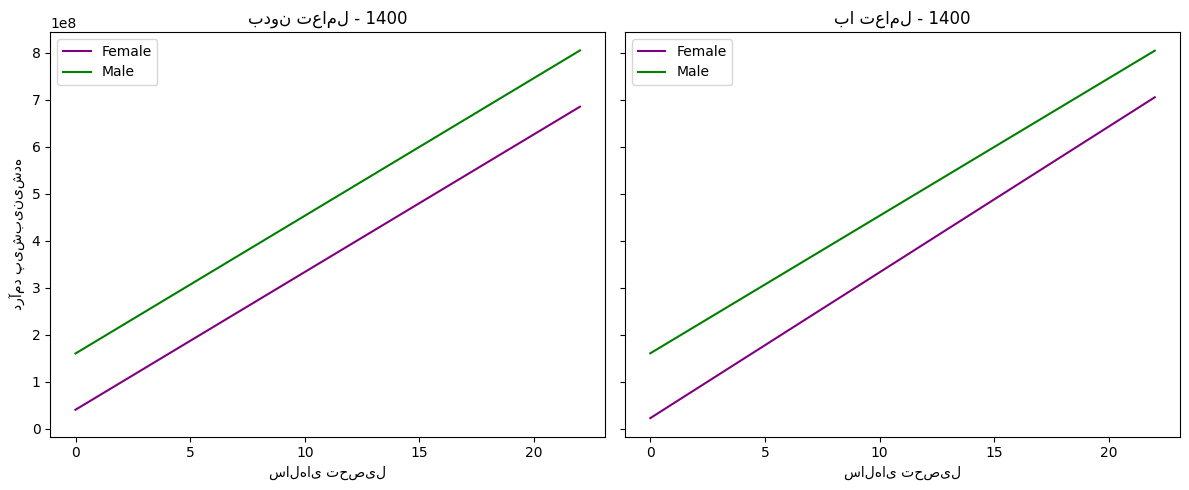


=== پردازش سال 1401 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.165
Model:                                  OLS   Adj. R-squared:                  0.165
Method:                       Least Squares   F-statistic:                     1379.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:48:51   Log-Likelihood:            -2.9559e+05
No. Observations:                     13945   AIC:                         5.912e+05
Df Residuals:                         13942   BIC:                         5.912e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
------------

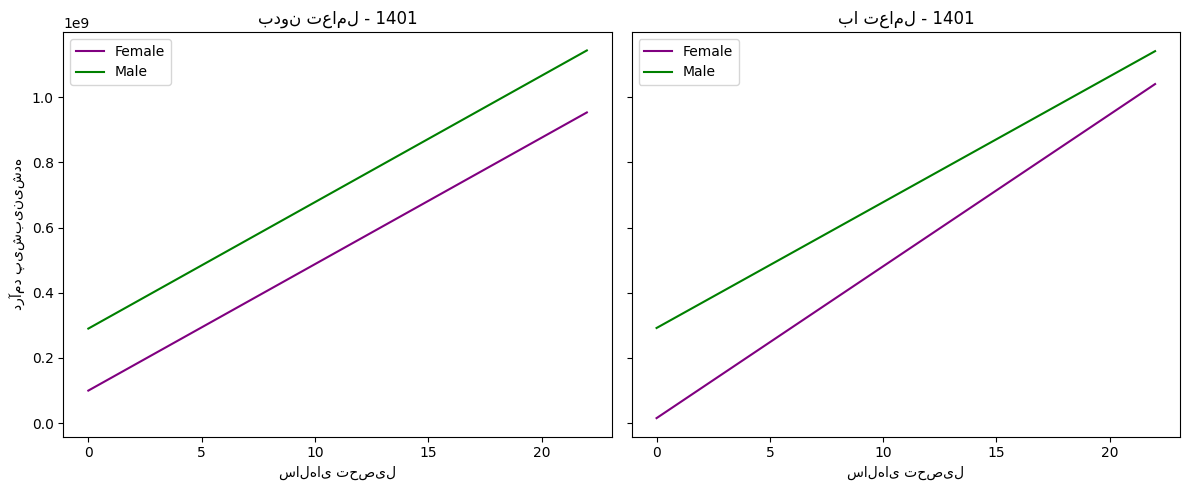


=== پردازش سال 1402 ===

---- مدل بدون تعامل ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.162
Model:                                  OLS   Adj. R-squared:                  0.162
Method:                       Least Squares   F-statistic:                     1289.
Date:                      Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                              03:48:59   Log-Likelihood:            -2.8823e+05
No. Observations:                     13359   AIC:                         5.765e+05
Df Residuals:                         13356   BIC:                         5.765e+05
Df Model:                                 2                                         
Covariance Type:                  nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
------------

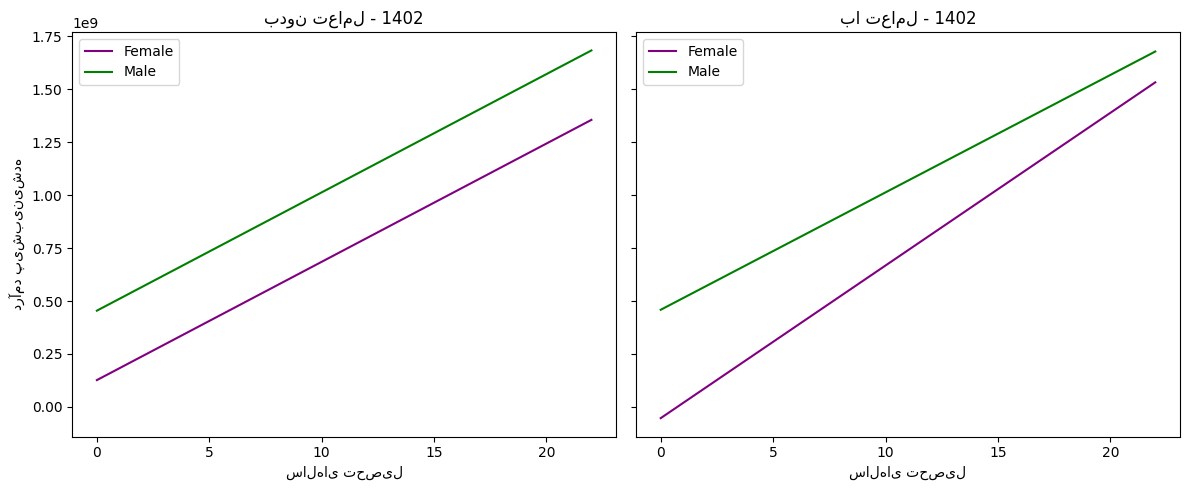

In [9]:
for year in range(1393, 1403):
    print(f"\n=== پردازش سال {year} ===")
    try:
        # ---------- بارگذاری داده‌ها ----------
        hbsir.setup(method="download_cleaned",download_source="mirror",years=[year])
        table = hbsir.load_table("Expenditures", years=[year])
        table = hbsir.add_attribute(table, name="Province")
        table = hbsir.add_attribute(table, name="County")
        table = hbsir.add_attribute(table, name="Urban_Rural")  # دیگه استفاده نمیشه، ولی نگه داشتم اگر لازم شد

        hhinc = hbsir.load_table("employment_income", years=[year])
        members = hbsir.load_table("members_properties", years=[year])

        # ---------- پردازش ----------
        df = members[(members["Member_Number"] == 1) &
                     (members["Education_Level"].isin(valid_levels))].copy()
        df["Years_Edu"] = df["Education_Level"].map(edu_map).astype(float)

        # اضافه کردن درآمد
        df = df.merge(
            hhinc[hhinc["Member_Number"] == 1][["ID", "Annual_Continuous_Income"]],
            on="ID", how="left"
        )

        # ستون جنسیت: فرض بر اینه که ستون Gender در members هست
        # Male -> 1, Female -> 0
        df["Gender_Binary"] = df["Sex"].apply(lambda x: 1 if str(x).lower() == "male" else 0)

        # حذف ردیف‌های بدون درآمد یا بدون جنسیت
        df = df.dropna(subset=["Annual_Continuous_Income", "Gender_Binary"])

        # ---------- مدل ----------
        model_no_inter = smf.ols("Annual_Continuous_Income ~ Years_Edu + Gender_Binary", data=df).fit()
        model_inter = smf.ols("Annual_Continuous_Income ~ Years_Edu * Gender_Binary", data=df).fit()

        print("\n---- مدل بدون تعامل ----")
        print(model_no_inter.summary())

        print("\n---- مدل با تعامل ----")
        print(model_inter.summary())

        # ---------- نمودار ----------
        years_range = np.linspace(df["Years_Edu"].min(), df["Years_Edu"].max(), 100)
        plot_df = pd.DataFrame({
            "Years_Edu": np.tile(years_range, 2),
            "Gender_Binary": np.repeat([0, 1], len(years_range))
        })
        plot_df["pred_no_inter"] = model_no_inter.predict(plot_df)
        plot_df["pred_inter"] = model_inter.predict(plot_df)

        fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
        for g, color, label in [(0, "purple", "Female"), (1, "green", "Male")]:
            subset = plot_df[plot_df["Gender_Binary"] == g]
            axes[0].plot(subset["Years_Edu"], subset["pred_no_inter"], color=color, label=label)
            axes[1].plot(subset["Years_Edu"], subset["pred_inter"], color=color, label=label)

        axes[0].set_title(f"بدون تعامل - {year}")
        axes[0].set_xlabel("سال‌های تحصیل")
        axes[0].set_ylabel("درآمد پیش‌بینی‌شده")
        axes[0].legend()

        axes[1].set_title(f"با تعامل - {year}")
        axes[1].set_xlabel("سال‌های تحصیل")
        axes[1].legend()

        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"⚠ خطا در پردازش سال {year}: {e}")
        continue


## Explore data schemas


In [10]:
import hbsir
import pandas as pd
from pandas.api.types import is_numeric_dtype

# ===== تنظیم سال‌ها =====
years = [1395]  # هر سالی که داری بگذار
hbsir.setup(method="download_cleaned",download_source="mirror",years=years)

def safe_call(fn, *args, **kwargs):
    try:
        return fn(*args, **kwargs)
    except Exception as e:
        return e  # برای تشخیص وجود/عدم وجود جدول

def pretty_preview(name, years, head_n=5, sample_n=5):
    print("\n" + "="*80)
    print(f"TABLE: {name}")
    print("="*80)
    df = safe_call(hbsir.load_table, name, years=years)
    if isinstance(df, Exception):
        print(f"❌ Cannot load '{name}': {df}")
        return None
    try:
        print(f"✅ Loaded '{name}' for years={years}")
        print(f"Shape: {df.shape}")
        print("Columns:", list(df.columns))
        # نمایش چند سطر اول
        print("\n-- head() --")
        print(df.head(head_n))
        # نمایش چند سطر تصادفی
        if len(df) > sample_n:
            print("\n-- sample() --")
            print(df.sample(sample_n, random_state=42))
        # خلاصه info
        print("\n-- info() --")
        buf = []
        df.info(buf=buf)
        print("\n".join(buf) if isinstance(buf, list) else buf)
    except Exception as e:
        print(f"⚠️ Preview error for '{name}': {e}")
    return df

# 1) تلاش برای یافتن تابع داخلی فهرست جداول
candidate_listers = ["list_tables", "available_tables", "tables", "catalog", "list_table_names"]
found_tables = []

for attr in candidate_listers:
    lister = getattr(hbsir, attr, None)
    if callable(lister):
        tables = safe_call(lister)
        if not isinstance(tables, Exception) and tables:
            # اگر خروجی DataFrame یا dict بود، تبدیل به فهرست
            if isinstance(tables, (list, tuple, set)):
                found_tables = sorted(set(map(str, tables)))
            elif isinstance(tables, pd.DataFrame) and "table" in tables.columns:
                found_tables = sorted(set(tables["table"].astype(str).tolist()))
            elif isinstance(tables, dict):
                found_tables = sorted(set(map(str, tables.keys())))
            else:
                # fallback: تلاش برای iterable بودن
                try:
                    found_tables = sorted(set(map(str, list(tables))))
                except:
                    pass
            if found_tables:
                print("✅ Found table list via:", attr)
                break

# 2) اگر هنوز چیزی نداریم، به‌صورت پروب: نام‌های متداول
if not found_tables:
    common_names = [
        "Expenditures", "employment_income", "members_properties", "household_properties",
        "income", "incomes", "expenditures", "expenditures_food", "expenditures_nonfood",
        "durables", "housing", "rent", "assets", "consumption", "health", "education",
        "price", "prices", "utilities", "transport", "vehicle", "agriculture", "loans",
        "savings", "insurance", "medical", "food", "nonfood"
    ]
    # پروب لود
    detected = []
    for name in common_names:
        df_try = safe_call(hbsir.load_table, name, years=years)
        if not isinstance(df_try, Exception):
            detected.append(name)
    found_tables = detected

# گزارش اولیه جدول‌ها
if found_tables:
    print("\n🗂  Discovered tables:")
    for t in found_tables:
        print(" -", t)
else:
    print("⛔️ No tables auto-discovered. If the package has docs, check exact table names. "
          "Otherwise tell me any one name that worked so I tune the probe set.")

# 3) پیش‌نمایش نمونه از هر جدول پیدا شده
for t in found_tables[:20]:  # اگر زیاد شد، محدود کن
    pretty_preview(t, years=years, head_n=5, sample_n=5)

# 4) اگر هیچ چیز پیدا نشد، نمونه‌هایی که خودت می‌دانی را مستقیم نشان بده:
# pretty_preview("Expenditures", years=[1395])
# pretty_preview("employment_income", years=[1395])
# pretty_preview("members_properties", years=[1395])



🗂  Discovered tables:
 - Expenditures
 - employment_income
 - members_properties
 - education
 - medical
 - food

TABLE: Expenditures
✅ Loaded 'Expenditures' for years=[1395]
Shape: (2555318, 9)
Columns: ['Year', 'ID', 'Table_Name', 'Commodity_Code', 'Provision_Method', 'Amount', 'Price', 'Gross_Expenditure', 'Net_Expenditure']

-- head() --
   Year           ID Table_Name  Commodity_Code Provision_Method Amount  \
0  1395  20001010534       food           11165         Purchase   24.0   
1  1395  20001010525       food           11112         Purchase  240.0   
2  1395  20001010525       food           11143         Purchase   24.0   
3  1395  20001010525       food           11151         Purchase  360.0   
4  1395  20001010525       food           11153         Purchase   24.0   

      Price  Gross_Expenditure  Net_Expenditure  
0   20000.0           480000.0         480000.0  
1  100000.0         24000000.0       24000000.0  
2   20000.0           480000.0         480000.0  
3   

ساخت شاخص برای قدرت خرید

## Prototype household welfare index: 1395


In [11]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

import hbsir

# -------------------------
# 1) Load & basic enrich
# -------------------------
hbsir.setup(method="download_cleaned",download_source="mirror",years=[1395])

exp = hbsir.load_table("Expenditures", years=[1395])
exp = hbsir.add_attribute(exp, name="Province")
exp = hbsir.add_attribute(exp, name="County")
exp = hbsir.add_attribute(exp, name="Urban_Rural")

inc = hbsir.load_table("employment_income", years=[1395])
mem = hbsir.load_table("members_properties", years=[1395])

# اگر نام ستون شناسه خانوار متفاوت است، اینجا یکسان‌سازی کن:
hh_key = "ID"  # فرض: ستون شناسه خانوار همین است

# -------------------------
# 2) Clean basics
# -------------------------
# تبدیل برخی ستون‌ها به عددی (در صورت وجود مقادیر متنی)
for col in ["Amount", "Price", "Gross_Expenditure", "Net_Expenditure"]:
    if col in exp.columns:
        exp[col] = pd.to_numeric(exp[col], errors="coerce")

# تیتر غذا و مسکن را مشخص کن:
# - اگر ستون Table_Name مثل نمونه‌ی تو وجود دارد و مقادیرش 'food' برای خوراک است
is_food = (exp.get("Table_Name", pd.Series(index=exp.index, dtype=object)) == "food")

# اگر کدهای مسکن/اجاره را داری، اینجا مشخص کن:
# مثلا Commodity_Code برای اجاره/مسکن:
is_housing = exp["Table_Name"] == "home"

# -------------------------
# 3) Regional price index (Province × Urban_Rural)
# -------------------------
# ایده: برای هر قلم، میانه قیمت ملی را بگیر؛ سپس برای هر منطقه، نسبت میانه قیمت منطقه به ملی را بگیر
# و در نهایت شاخص قیمت منطقه را میانه این نسبت‌ها در سبد مشترک قرار دهیم.
# برای پایداری، اقلام با تعداد مشاهده کم را حذف می‌کنیم.

# فقط اقلامی که هم قیمت و هم مبلغ دارند
price_df = exp.dropna(subset=["Price", "Commodity_Code"]).copy()

# میانه قیمت ملی هر قلم
nat_price = (price_df
             .groupby("Commodity_Code")["Price"]
             .median()
             .rename("Nat_MedPrice"))

price_df = price_df.merge(nat_price, on="Commodity_Code", how="left")
price_df = price_df[(price_df["Nat_MedPrice"] > 0) & (price_df["Price"] > 0)]
price_df["RelPrice"] = price_df["Price"] / price_df["Nat_MedPrice"]

# منطقه = Province × Urban_Rural
price_df["Region"] = price_df["Province"].astype(str) + " | " + price_df["Urban_Rural"].astype(str)

# برای هر Region×Commodity_Code نسبت میانه قیمت
reg_item_rel = (price_df
                .groupby(["Region", "Commodity_Code"])["RelPrice"]
                .median()
                .reset_index())

# برای ساخت شاخص منطقه‌ای، میانه بین اقلامِ با داده مشترک
reg_pindex = (reg_item_rel
              .groupby("Region")["RelPrice"]
              .median()
              .rename("Region_PriceIndex")
              .reset_index())

# اگر خواستی وزن‌دهی کنی، می‌تونی به‌جای میانه، متوسط موزون با سهم هزینه ملی کار کنی.

# به exp وصل کن تا هر ردیف خرج، شاخص منطقه‌اش را داشته باشد
exp["Region"] = exp["Province"].astype(str) + " | " + exp["Urban_Rural"].astype(str)
exp = exp.merge(reg_pindex, on="Region", how="left")

# اگر شاخصی نبود (NaN)، 1 بگذار
exp["Region_PriceIndex"] = exp["Region_PriceIndex"].fillna(1.0)

# -------------------------
# 4) Household-level aggregation (real expenditures)
# -------------------------
# مخارج واقعی = Net_Expenditure / Region_PriceIndex  (اگر Net نیست، از Gross استفاده کن)
exp["Use_Exp"] = exp["Net_Expenditure"].fillna(exp["Gross_Expenditure"])
exp["Real_Exp"] = exp["Use_Exp"] / exp["Region_PriceIndex"]

# مجموع مخارج خانوار
hh_exp = exp.groupby(hh_key, as_index=False).agg(
    total_exp=("Use_Exp", "sum"),
    real_total_exp=("Real_Exp", "sum"),
    food_exp=("Use_Exp", lambda s: s[is_food.loc[s.index]].sum() if len(s)>0 else 0.0),
    housing_exp=("Use_Exp", lambda s: s[is_housing.loc[s.index]].sum() if len(s)>0 else 0.0)
)

# سهم‌ها
hh_exp["food_share"] = np.where(hh_exp["total_exp"]>0, hh_exp["food_exp"]/hh_exp["total_exp"], np.nan)
hh_exp["rent_burden"] = np.where(hh_exp["total_exp"]>0, hh_exp["housing_exp"]/hh_exp["total_exp"], np.nan)

# -------------------------
# 5) Income aggregation (and real income via same region index)
# -------------------------
# در جدول درآمد ممکن است ستون‌ها متفاوت باشند. چند سناریو:
# - اگر ستونی مانند 'Total_Income' یا 'Net_Income' داری، همان را بگیر.
# - اگر پراکنده است، کل ستون‌های عددی را جمع کن (به جز سال/شناسه).
inc = inc.copy()

from pandas.api.types import is_numeric_dtype

num_cols = [c for c in inc.columns if c not in [hh_key, "Year"] and is_numeric_dtype(inc[c])]

if len(num_cols) == 0:
    # اگر ستونی عددی پیدا نشد، این خط را با ستون صحیحت جایگزین کن:
    num_cols = []

hh_inc = inc.groupby(hh_key, as_index=False)[num_cols].sum() if num_cols else pd.DataFrame(columns=[hh_key, "income_total"])
if not num_cols:
    hh_inc["income_total"] = np.nan
else:
    hh_inc["income_total"] = hh_inc[num_cols].sum(axis=1)

# پیوند برای دریافت Region_PriceIndex خانوار (از جدول exp)
hh_region = exp[[hh_key, "Region"]].drop_duplicates()
hh_region = hh_region.merge(reg_pindex, on="Region", how="left").fillna({"Region_PriceIndex":1.0})

hh_inc = hh_inc.merge(hh_region[[hh_key, "Region_PriceIndex"]], on=hh_key, how="left")
hh_inc["Region_PriceIndex"] = hh_inc["Region_PriceIndex"].fillna(1.0)
hh_inc["real_income"] = hh_inc["income_total"] / hh_inc["Region_PriceIndex"]

# -------------------------
# 6) Household size & OECD equivalence
# -------------------------
# از جدول اعضا شمارش کن. اگر ستون Age داری، کودک را <14 در نظر بگیر.
size = mem.groupby(hh_key).size().rename("hh_size").reset_index()

if "Age" in mem.columns:
    tmp = mem[[hh_key, "Age"]].copy()
    tmp["is_child"] = (pd.to_numeric(tmp["Age"], errors="coerce") < 14).astype("int")
    children = tmp.groupby(hh_key)["is_child"].sum().rename("n_children").reset_index()
    demo = size.merge(children, on=hh_key, how="left").fillna({"n_children":0})
else:
    # اگر سن نداری، کودک=0 بگیر
    demo = size.copy()
    demo["n_children"] = 0

demo["n_adults"] = demo["hh_size"] - demo["n_children"]
demo.loc[demo["n_adults"]<0, "n_adults"] = 0

# OECD equivalence scale
demo["eq_size"] = 1 + 0.5*np.maximum(demo["n_adults"]-1, 0) + 0.3*demo["n_children"]
demo.loc[demo["eq_size"]<=0, "eq_size"] = demo["hh_size"].replace(0, 1)

# -------------------------
# 7) Merge all & build features
# -------------------------
df = hh_exp.merge(hh_inc[[hh_key, "income_total", "real_income"]], on=hh_key, how="left")
df = df.merge(demo[[hh_key, "hh_size", "eq_size"]], on=hh_key, how="left")

# سرانه معادل‌سازی‌شده (واقعی)
df["real_exp_pc"] = df["real_total_exp"] / df["eq_size"]
df["real_inc_pc"] = df["real_income"] / df["eq_size"]

# لاگ‌ها (پیشگیری از صفر/منفی)
for col in ["real_exp_pc", "real_inc_pc"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df[col] = df[col].replace([np.inf, -np.inf], np.nan)

df["log_real_exp_pc"] = np.log(df["real_exp_pc"].clip(lower=1))  # اگر خیلی کوچک است، 1 بگذار
df["log_real_inc_pc"] = np.log(df["real_inc_pc"].clip(lower=1))

# تمیزکاری سهم‌ها
for col in ["food_share", "rent_burden"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce").clip(lower=0, upper=1)

# -------------------------
# 8) Baseline PPI (ساده)
# -------------------------
# استانداردسازی لاگ مخارج واقعی سرانه
baseline = df[["log_real_exp_pc"]].copy()
baseline_std = (baseline - baseline.mean())/baseline.std(ddof=0)
df["PPI_baseline"] = baseline_std["log_real_exp_pc"]

# -------------------------
# 9) Composite PPI via PCA
# -------------------------
feature_cols = ["log_real_exp_pc", "log_real_inc_pc"]
if "food_share" in df.columns:
    df["one_minus_food"] = 1 - df["food_share"]
    feature_cols.append("one_minus_food")
if "rent_burden" in df.columns and df["rent_burden"].notna().any():
    df["one_minus_rent"] = 1 - df["rent_burden"]
    feature_cols.append("one_minus_rent")

X = df[feature_cols].copy()
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())  # یا هر استراتژی دلخواه

scaler = StandardScaler()
X_std = scaler.fit_transform(X)

pca = PCA(n_components=1, random_state=42)
df["PPI_pca"] = pca.fit_transform(X_std).ravel()

# نرمال‌سازی به zscore برای خوانایی
df["PPI_pca_z"] = (df["PPI_pca"] - df["PPI_pca"].mean()) / df["PPI_pca"].std(ddof=0)

# -------------------------
# 10) خروجی نهایی
# -------------------------
out_cols = [hh_key, "Province", "Urban_Rural", "hh_size", "eq_size",
            "real_total_exp", "real_income", "real_exp_pc", "real_inc_pc",
            "food_share", "rent_burden", "PPI_baseline", "PPI_pca_z"]

# الحاق Province/Urban_Rural از exp
hh_geo = exp[[hh_key, "Province", "Urban_Rural"]].drop_duplicates()
res = df.merge(hh_geo, on=hh_key, how="left")

res_final = res[out_cols].drop_duplicates()
res_final = res_final.sort_values("PPI_pca_z", ascending=False)

print(res_final.head(10))
# res_final.to_csv("ppi_1395.csv", index=False)


e:\reg-pro\.venv\lib\site-packages\pandas\core\arrays\masked.py:691: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs2, **kwargs)


                ID                Province Urban_Rural  hh_size  eq_size  \
13648  12301496735                  Tehran       Urban        2      1.5   
12881  12203468120               Hormozgan       Urban        3      2.0   
9651   11603353432                    Ilam       Urban        1      1.0   
1763   10303067126         East_Azerbaijan       Urban        4      2.5   
7067   11105258835  Sistan_and_Baluchestan       Urban        3      1.8   
3085   10505113521              Kermanshah       Urban        2      1.5   
13431  12301492320                  Tehran       Urban        3      2.0   
12960  12204469521               Hormozgan       Urban        4      2.3   
18535  13001649628                  Alborz       Urban        2      1.5   
7955   11302295030                 Hamadan       Urban        4      2.3   

          real_total_exp        real_income        real_exp_pc  \
13648  2412844565.887443   3103089033.15611  1608563043.924962   
12881  1732448418.436011  61767

## Inspect expenditure categories


In [12]:
print(exp["Table_Name"].dropna().value_counts().head(20))
print(sorted(exp["Table_Name"].dropna().unique())[:50])


Table_Name
food              1231814
durable            443763
furniture          204035
miscellaneous      163944
home               154517
transportation      89413
cloth               68676
communication       63570
medical             62074
entertainment       33051
hotel               32827
tobacco              7634
Name: count, dtype: int64
['cloth', 'communication', 'durable', 'entertainment', 'food', 'furniture', 'home', 'hotel', 'medical', 'miscellaneous', 'tobacco', 'transportation']


## Housing-share diagnostic


In [13]:
# یک خانوار که rent_burden>0 دارد
hid = res_final.loc[res_final["rent_burden"]>0, "ID"].iloc[0]

# جمع هزینه‌های "مسکن" از جدول ریز اقلام
mask_housing = (exp["Table_Name"]=="home")  # اگر اسم دسته فرق می‌کند، این را اصلاح کن
sum_housing = exp.loc[(exp["ID"]==hid) & mask_housing, "Use_Exp"].sum()

# کل هزینه خانوار از ریز اقلام
sum_total = exp.loc[exp["ID"]==hid, "Use_Exp"].sum()

print("rent_burden (از جدول نهایی):",
      res_final.loc[res_final["ID"]==hid, "rent_burden"].item())
print("سهم مسکن محاسبه‌شده از ریزاقلام:", sum_housing / sum_total if sum_total>0 else None)


rent_burden (از جدول نهایی): 0.18298940035530334
سهم مسکن محاسبه‌شده از ریزاقلام: 0.18298940035530334


## Numeric log conversion


In [14]:
def safe_log_series(s, eps=1.0):
    s = pd.to_numeric(s, errors="coerce").astype("float64")
    s = s.replace([np.inf, -np.inf], np.nan)
    s = s.clip(lower=eps)
    return np.log(s)

df["log_real_exp_pc"] = safe_log_series(df["real_exp_pc"], eps=1.0)
df["log_real_inc_pc"] = safe_log_series(df["real_inc_pc"], eps=1.0)


## Check derived columns


In [15]:
print("log cols in df?", {"log_real_exp_pc" in df.columns, "log_real_inc_pc" in df.columns})


log cols in df? {True}


## Assemble diagnostic output


In [16]:
# اگر قبلاً hh_geo داری:
hh_geo = exp[[hh_key, "Province", "Urban_Rural"]].drop_duplicates()

# res را تازه بساز تا ستون‌های جدید df منتقل شوند
res = df.merge(hh_geo, on=hh_key, how="left")

out_cols = [
    hh_key, "Province", "Urban_Rural", "hh_size", "eq_size",
    "real_total_exp", "real_income", "real_exp_pc", "real_inc_pc",
    "log_real_exp_pc", "log_real_inc_pc",   # ⬅️ حتماً اضافه باشد
    "food_share", "rent_burden",
    "PPI_baseline", "PPI_pca_z"
]

missing = [c for c in out_cols if c not in res.columns]
print("MISSING in res:", missing)  # باید لیست خالی بده

res_final = res[out_cols].drop_duplicates()


MISSING in res: []


## Inspect transformed features


In [17]:
print(res_final[["log_real_exp_pc","log_real_inc_pc","PPI_pca_z"]].head())


   log_real_exp_pc  log_real_inc_pc  PPI_pca_z
0        17.539500        17.399961  -0.905445
1        17.318614        17.880120  -1.009203
2        18.037398              NaN   0.833776
3        17.657840              NaN   0.060796
4        18.089748              NaN   0.785434


## Feature correlations


In [18]:
cols = ["PPI_pca_z", "PPI_baseline", "log_real_exp_pc", "log_real_inc_pc", "food_share", "rent_burden"]
print(res_final[cols].corr())



                 PPI_pca_z  PPI_baseline  log_real_exp_pc  log_real_inc_pc  \
PPI_pca_z         1.000000      0.717743         0.717743         0.795045   
PPI_baseline      0.717743      1.000000         1.000000         0.387103   
log_real_exp_pc   0.717743      1.000000         1.000000         0.387103   
log_real_inc_pc   0.795045      0.387103         0.387103         1.000000   
food_share       -0.823978     -0.480473        -0.480473        -0.372547   
rent_burden       0.174049     -0.189795        -0.189795        -0.029205   

                 food_share  rent_burden  
PPI_pca_z         -0.823978     0.174049  
PPI_baseline      -0.480473    -0.189795  
log_real_exp_pc   -0.480473    -0.189795  
log_real_inc_pc   -0.372547    -0.029205  
food_share         1.000000    -0.247381  
rent_burden       -0.247381     1.000000  


## Index distribution


In [19]:
print(res_final["PPI_pca_z"].describe())


count    3.814600e+04
mean     5.960616e-17
std      1.000013e+00
min     -1.076947e+01
25%     -5.979589e-01
50%      3.624104e-02
75%      6.348475e-01
max      4.254729e+00
Name: PPI_pca_z, dtype: float64


## Urban-rural index means


In [20]:
print(res_final.groupby("Urban_Rural")["PPI_pca_z"].mean())


Urban_Rural
Rural   -0.392781
Urban    0.403807
Name: PPI_pca_z, dtype: float64


## Province-level index means


In [21]:
prov_mean = res_final.groupby("Province")["PPI_pca_z"].mean().sort_values(ascending=False)
print(prov_mean.head(10))
print(prov_mean.tail(10))


Province
Tehran             0.962068
Alborz             0.588572
Isfahan            0.348500
Yazd               0.345406
Mazandaran         0.338534
Qom                0.296855
East_Azerbaijan    0.163300
Gilan              0.136760
Bushehr            0.120693
Fars               0.114785
Name: PPI_pca_z, dtype: float64
Province
West_Azerbaijan              -0.159815
North_Khorasan               -0.185664
Kohgiluyeh_and_Boyer_Ahmad   -0.186667
Ardabil                      -0.200121
Ilam                         -0.263385
South_Khorasan               -0.277794
Kerman                       -0.279636
Hormozgan                    -0.297423
Kurdistan                    -0.305974
Sistan_and_Baluchestan       -1.143380
Name: PPI_pca_z, dtype: float64


## Welfare models across years



=== پردازش سال 1393 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     7.615
Date:                Sat, 27 Sep 2025   Prob (F-statistic):           0.000494
Time:                        03:57:29   Log-Likelihood:                -43656.
No. Observations:               27619   AIC:                         8.732e+04
Df Residuals:                   27616   BIC:                         8.734e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------

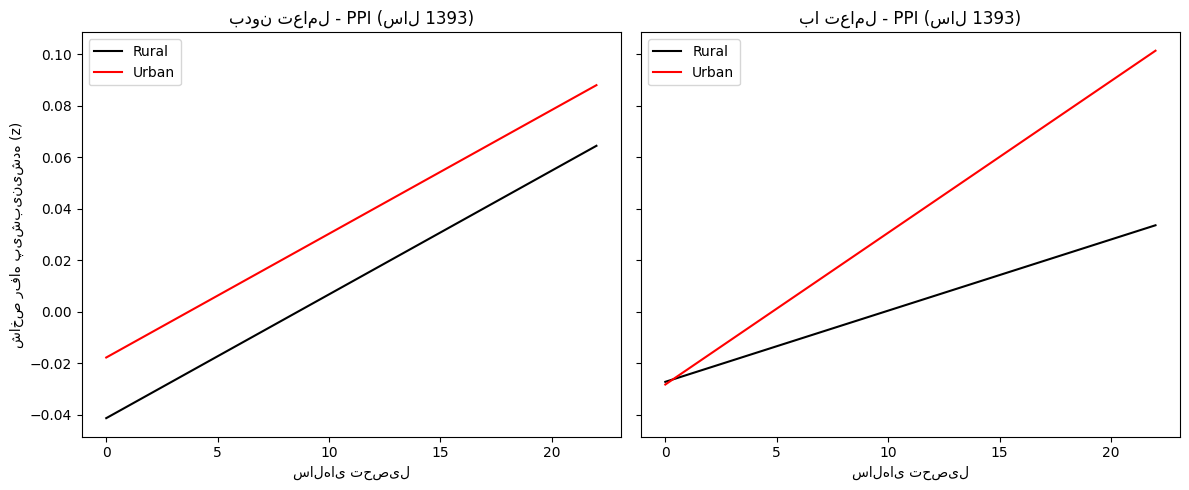


=== پردازش سال 1394 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.072
Model:                            OLS   Adj. R-squared:                  0.072
Method:                 Least Squares   F-statistic:                     1072.
Date:                Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                        03:58:25   Log-Likelihood:                -40243.
No. Observations:               27543   AIC:                         8.049e+04
Df Residuals:                   27540   BIC:                         8.052e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------

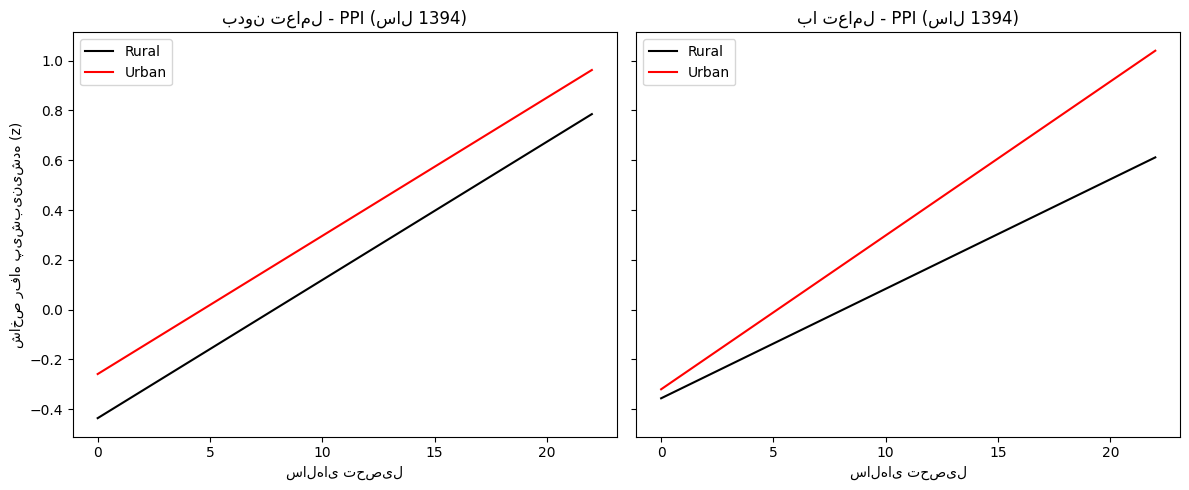


=== پردازش سال 1395 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.009
Model:                            OLS   Adj. R-squared:                  0.009
Method:                 Least Squares   F-statistic:                     119.0
Date:                Sat, 27 Sep 2025   Prob (F-statistic):           3.53e-52
Time:                        03:59:21   Log-Likelihood:                -43108.
No. Observations:               27483   AIC:                         8.622e+04
Df Residuals:                   27480   BIC:                         8.625e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------

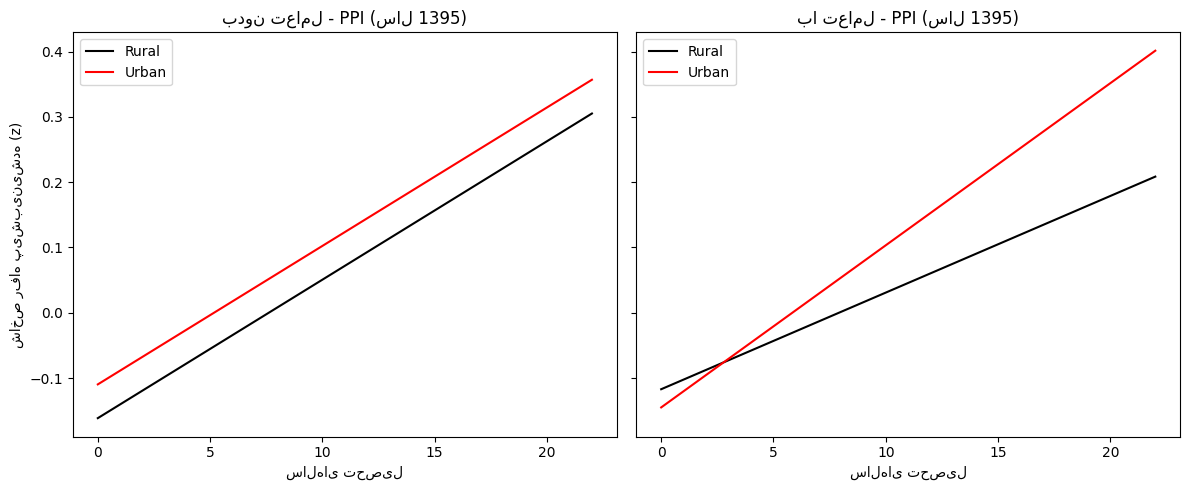


=== پردازش سال 1396 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.152
Model:                            OLS   Adj. R-squared:                  0.152
Method:                 Least Squares   F-statistic:                     2472.
Date:                Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                        04:00:11   Log-Likelihood:                -37596.
No. Observations:               27600   AIC:                         7.520e+04
Df Residuals:                   27597   BIC:                         7.522e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------

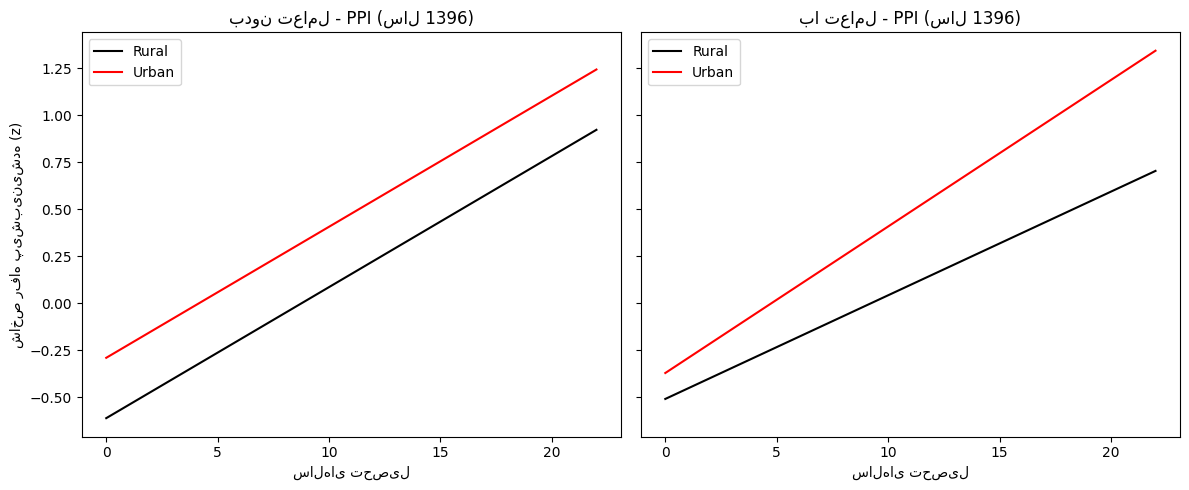


=== پردازش سال 1397 ===
⚠ خطا در پردازش سال 1397: File is not a zip file

=== پردازش سال 1398 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                  0.002
Method:                 Least Squares   F-statistic:                     32.97
Date:                Sat, 27 Sep 2025   Prob (F-statistic):           5.00e-15
Time:                        04:01:12   Log-Likelihood:                -44968.
No. Observations:               28952   AIC:                         8.994e+04
Df Residuals:                   28949   BIC:                         8.997e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.0

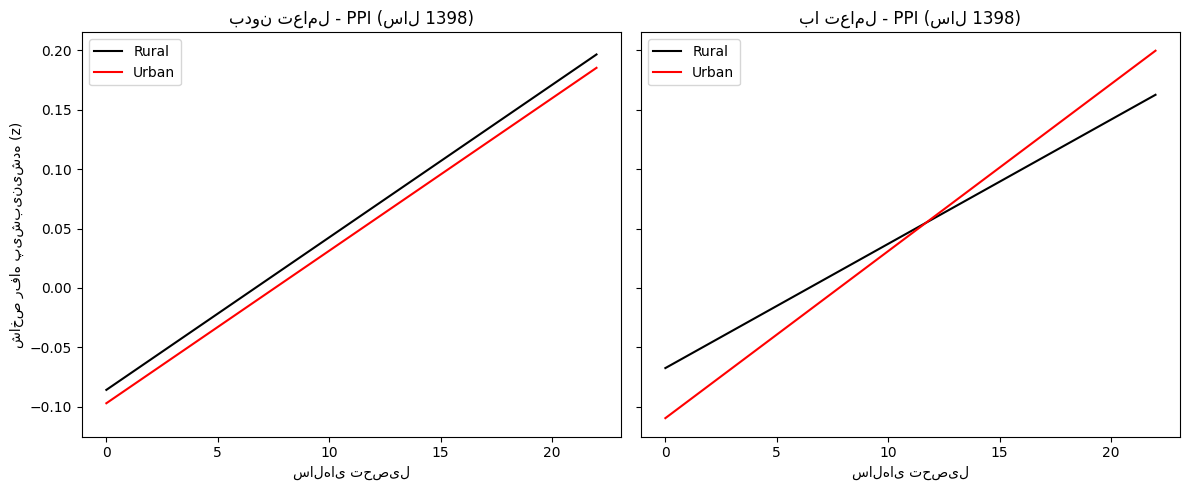


=== پردازش سال 1399 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.006
Model:                            OLS   Adj. R-squared:                  0.006
Method:                 Least Squares   F-statistic:                     82.79
Date:                Sat, 27 Sep 2025   Prob (F-statistic):           1.41e-36
Time:                        04:02:03   Log-Likelihood:                -44550.
No. Observations:               28894   AIC:                         8.911e+04
Df Residuals:                   28891   BIC:                         8.913e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------

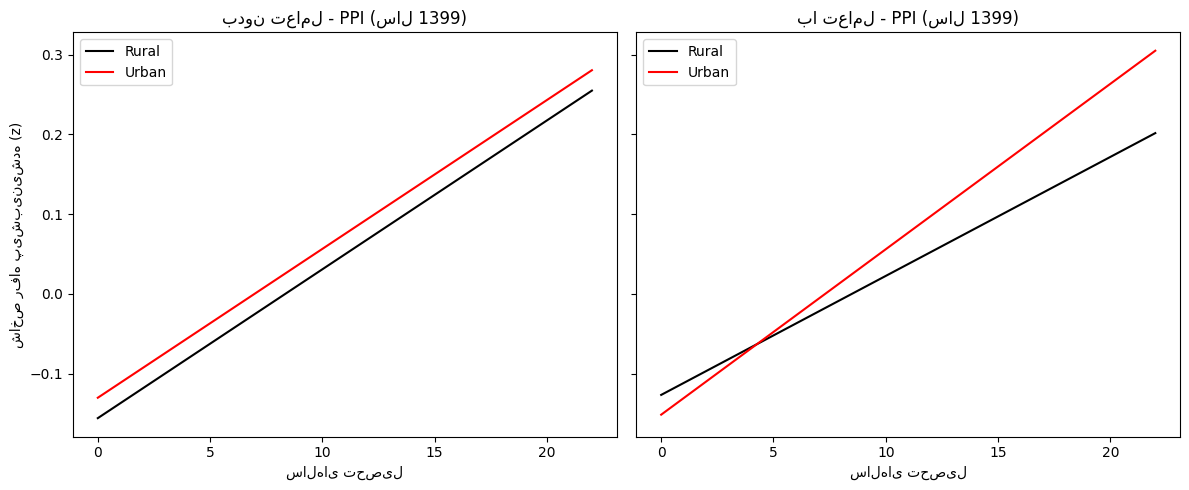


=== پردازش سال 1400 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.131
Model:                            OLS   Adj. R-squared:                  0.131
Method:                 Least Squares   F-statistic:                     2218.
Date:                Sat, 27 Sep 2025   Prob (F-statistic):               0.00
Time:                        04:02:54   Log-Likelihood:                -40221.
No. Observations:               29397   AIC:                         8.045e+04
Df Residuals:                   29394   BIC:                         8.047e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------

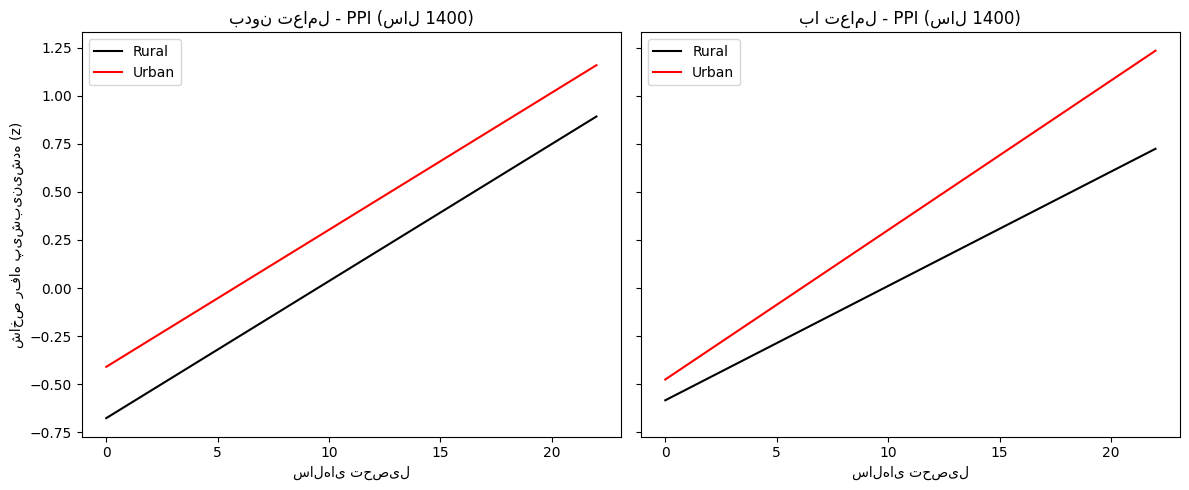


=== پردازش سال 1401 ===


C:\Users\tadbirsabz\AppData\Local\Temp\ipykernel_20076\2941915473.py:71: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  exp["Region_PriceIndex"] = exp["Region_PriceIndex"].fillna(1.0)
C:\Users\tadbirsabz\AppData\Local\Temp\ipykernel_20076\2941915473.py:96: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  hh_region = hh_region.merge(reg_pindex, on="Region", how="left").fillna({"Region_PriceIndex":1.0})



---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.010
Model:                            OLS   Adj. R-squared:                  0.009
Method:                 Least Squares   F-statistic:                     140.4
Date:                Sat, 27 Sep 2025   Prob (F-statistic):           2.15e-61
Time:                        04:03:43   Log-Likelihood:                -44291.
No. Observations:               29240   AIC:                         8.859e+04
Df Residuals:                   29237   BIC:                         8.861e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Inter

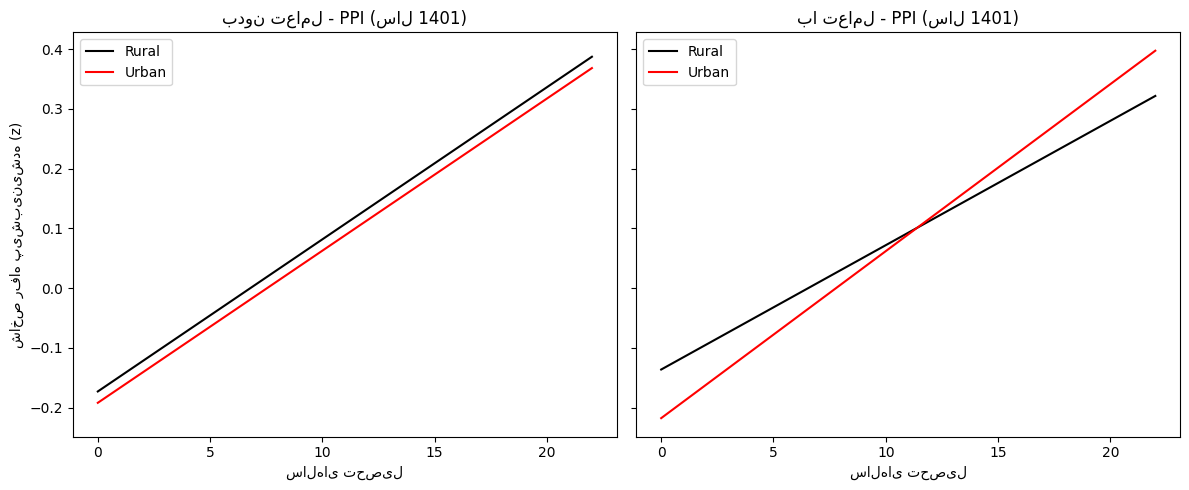


=== پردازش سال 1402 ===


C:\Users\tadbirsabz\AppData\Local\Temp\ipykernel_20076\2941915473.py:71: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  exp["Region_PriceIndex"] = exp["Region_PriceIndex"].fillna(1.0)
C:\Users\tadbirsabz\AppData\Local\Temp\ipykernel_20076\2941915473.py:96: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  hh_region = hh_region.merge(reg_pindex, on="Region", how="left").fillna({"Region_PriceIndex":1.0})



---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.000
Method:                 Least Squares   F-statistic:                    0.9525
Date:                Sat, 27 Sep 2025   Prob (F-statistic):              0.386
Time:                        04:04:34   Log-Likelihood:                -45099.
No. Observations:               29079   AIC:                         9.020e+04
Df Residuals:                   29076   BIC:                         9.023e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Inter

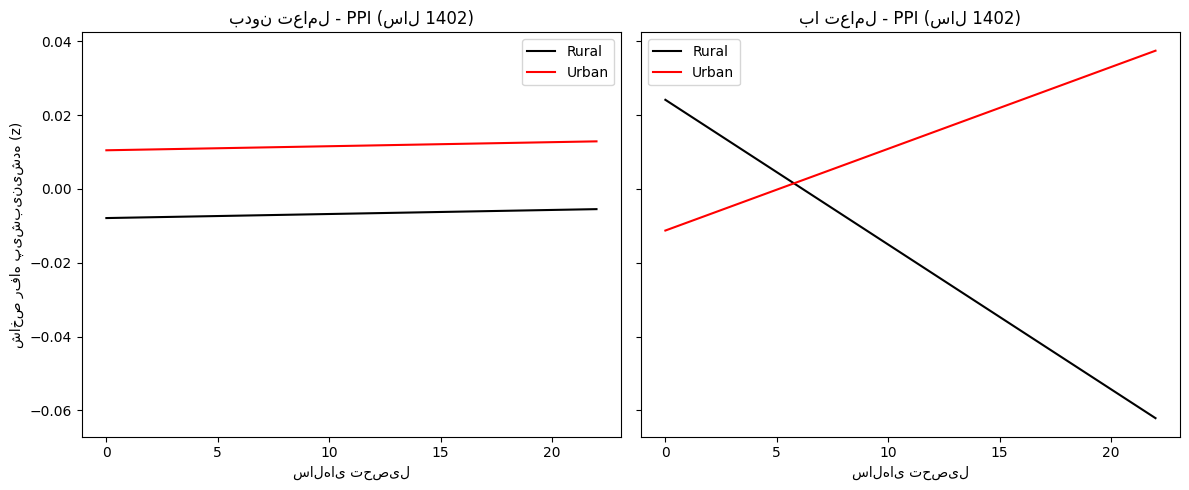

In [23]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

import hbsir
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# ---------------------------
# Helpers
# ---------------------------
def winsorize(s, low_q=0.01, high_q=0.99):
    lo, hi = s.quantile(low_q), s.quantile(high_q)
    return s.clip(lower=lo, upper=hi)

def safe_log_series(s, eps=1.0):
    s = pd.to_numeric(s, errors="coerce").astype("float64")
    s = s.replace([np.inf, -np.inf], np.nan)
    s = s.clip(lower=eps)
    return np.log(s)

from pandas.api.types import is_numeric_dtype
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

def cast_numeric(df: pd.DataFrame) -> pd.DataFrame:
    """هر ستونی که عددی باشد را به float64 استاندارد تبدیل می‌کند (رفع UInt8Dtype و ...)."""
    for c in df.columns:
        if is_numeric_dtype(df[c]):
            df[c] = pd.to_numeric(df[c], errors="coerce").astype("float64")
    return df

def build_ppi_for_year(year):
    """PPI (PCA) را برای هر خانوار در سالِ ورودی می‌سازد و برمی‌گرداند."""
    hbsir.setup(years=[year])

    # --- Load
    exp = hbsir.load_table("Expenditures", years=[year])
    exp = hbsir.add_attribute(exp, name="Province")
    exp = hbsir.add_attribute(exp, name="County")
    exp = hbsir.add_attribute(exp, name="Urban_Rural")

    inc = hbsir.load_table("employment_income", years=[year])
    mem = hbsir.load_table("members_properties", years=[year])

    # --- Cast numeric to float64 (fix UInt8Dtype)
    exp = cast_numeric(exp)
    inc = cast_numeric(inc)
    mem = cast_numeric(mem)

    hh_key = "ID"

    # --- Category flags
    is_food = (exp.get("Table_Name", pd.Series(index=exp.index, dtype=object)) == "food")
    is_housing = (exp.get("Table_Name", pd.Series(index=exp.index, dtype=object)) == "home")

    # --- Regional price index (Province × Urban_Rural)
    price_df = exp.dropna(subset=["Price", "Commodity_Code"]).copy()
    nat_price = price_df.groupby("Commodity_Code")["Price"].median().rename("Nat_MedPrice")
    price_df = price_df.merge(nat_price, on="Commodity_Code", how="left")
    price_df = price_df[(price_df["Nat_MedPrice"] > 0) & (price_df["Price"] > 0)]
    price_df["RelPrice"] = price_df["Price"] / price_df["Nat_MedPrice"]
    price_df["Region"] = price_df["Province"].astype(str) + " | " + price_df["Urban_Rural"].astype(str)
    reg_item_rel = (price_df.groupby(["Region", "Commodity_Code"])["RelPrice"].median().reset_index())
    reg_pindex = (reg_item_rel.groupby("Region")["RelPrice"].median()
                  .rename("Region_PriceIndex").reset_index())

    exp["Region"] = exp["Province"].astype(str) + " | " + exp["Urban_Rural"].astype(str)
    exp = exp.merge(reg_pindex, on="Region", how="left")
    exp["Region_PriceIndex"] = exp["Region_PriceIndex"].fillna(1.0)

    # --- Real expenditures
    exp["Use_Exp"] = exp["Net_Expenditure"].fillna(exp["Gross_Expenditure"])
    exp["Real_Exp"] = exp["Use_Exp"] / exp["Region_PriceIndex"]

    hh_exp = exp.groupby(hh_key, as_index=False).agg(
        total_exp=("Use_Exp", "sum"),
        real_total_exp=("Real_Exp", "sum"),
        food_exp=("Use_Exp", lambda s: s[is_food.loc[s.index]].sum() if len(s) else 0.0),
        housing_exp=("Use_Exp", lambda s: s[is_housing.loc[s.index]].sum() if len(s) else 0.0),
    )
    hh_exp["food_share"]   = np.where(hh_exp["total_exp"]>0, hh_exp["food_exp"]/hh_exp["total_exp"], np.nan)
    hh_exp["rent_burden"]  = np.where(hh_exp["total_exp"]>0, hh_exp["housing_exp"]/hh_exp["total_exp"], np.nan)

    # --- Real income (sum all numeric cols safely)
    num_cols = [c for c in inc.columns if c not in [hh_key, "Year"] and is_numeric_dtype(inc[c])]
    if len(num_cols) == 0:
        hh_inc = inc[[hh_key]].drop_duplicates().copy()
        hh_inc["income_total"] = np.nan
    else:
        hh_inc = inc.groupby(hh_key, as_index=False)[num_cols].sum()
        hh_inc["income_total"] = hh_inc[num_cols].sum(axis=1)

    hh_region = exp[[hh_key, "Region"]].drop_duplicates()
    hh_region = hh_region.merge(reg_pindex, on="Region", how="left").fillna({"Region_PriceIndex":1.0})
    hh_inc = hh_inc.merge(hh_region[[hh_key, "Region_PriceIndex"]], on=hh_key, how="left")
    hh_inc["Region_PriceIndex"] = hh_inc["Region_PriceIndex"].fillna(1.0)
    hh_inc["real_income"] = hh_inc["income_total"] / hh_inc["Region_PriceIndex"]

    # --- Household size & equivalence
    size = mem.groupby(hh_key).size().rename("hh_size").reset_index()
    if "Age" in mem.columns:
        tmp = mem[[hh_key, "Age"]].copy()
        tmp["is_child"] = (pd.to_numeric(tmp["Age"], errors="coerce") < 14).astype("int")
        children = tmp.groupby(hh_key)["is_child"].sum().rename("n_children").reset_index()
        demo = size.merge(children, on=hh_key, how="left").fillna({"n_children":0})
        demo["n_adults"] = (demo["hh_size"] - demo["n_children"]).clip(lower=0)
        demo["eq_size"]  = 1 + 0.5*np.maximum(demo["n_adults"]-1, 0) + 0.3*demo["n_children"]
        demo.loc[demo["eq_size"]<=0, "eq_size"] = demo["hh_size"].replace(0,1)
    else:
        demo = size.copy()
        demo["eq_size"] = np.sqrt(np.maximum(demo["hh_size"], 1))

    # --- Merge & features
    df = hh_exp.merge(hh_inc[[hh_key, "real_income"]], on=hh_key, how="left")
    df = df.merge(demo[[hh_key, "hh_size", "eq_size"]], on=hh_key, how="left")

    df["real_exp_pc"] = df["real_total_exp"] / df["eq_size"]
    df["real_inc_pc"] = df["real_income"]    / df["eq_size"]

    # پایداری
    df["real_exp_pc"] = winsorize(pd.to_numeric(df["real_exp_pc"], errors="coerce"))
    df["real_inc_pc"] = winsorize(pd.to_numeric(df["real_inc_pc"], errors="coerce"))

    df["log_real_exp_pc"] = safe_log_series(df["real_exp_pc"], eps=1.0)
    df["log_real_inc_pc"] = safe_log_series(df["real_inc_pc"], eps=1.0)

    df["one_minus_food"] = 1 - pd.to_numeric(df["food_share"],  errors="coerce")
    df["one_minus_rent"] = 1 - pd.to_numeric(df["rent_burden"], errors="coerce")

    feature_cols = ["log_real_exp_pc", "log_real_inc_pc", "one_minus_food", "one_minus_rent"]
    X = df[feature_cols].replace([np.inf, -np.inf], np.nan).fillna(df[feature_cols].median())

    scaler = StandardScaler()
    X_std = scaler.fit_transform(X)

    pca = PCA(n_components=1, random_state=42)
    df["PPI_pca"]   = pca.fit_transform(X_std).ravel()
    df["PPI_pca_z"] = (df["PPI_pca"] - df["PPI_pca"].mean()) / df["PPI_pca"].std(ddof=0)
    df["PPI_score"] = 100 + 15*df["PPI_pca_z"]

    geo = exp[[hh_key, "Urban_Rural", "Province"]].drop_duplicates()
    df = df.merge(geo, on=hh_key, how="left")

    return df[[hh_key, "PPI_pca_z", "PPI_score", "Urban_Rural", "Province"]].drop_duplicates()



# ---------------------------
# نگاشت تحصیلات → سال‌های تحصیل (Fallback اگر نداشتی)
# ---------------------------
# اگر قبلاً valid_levels و edu_map را تعریف کرده‌ای، همین‌ها نادیده گرفته می‌شوند.
try:
    valid_levels  # type: ignore
    edu_map       # type: ignore
except NameError:
    valid_levels = [
    "Unofficial",             
    "Primary",                
    "Lower_Secondary",        
    "Higher_Secondary",       
    "Pre_University",         
    "Short_Cycle_Tertiary",   
    "Bachelors",              
    "Masters",                
    "Doctoral"                
]
    edu_map = {
    "Unofficial": 0,
    "Primary": 5,
    "Lower_Secondary": 8,
    "Higher_Secondary": 12,
    "Pre_University": 13,
    "Short_Cycle_Tertiary": 14,
    "Bachelors": 16,
    "Masters": 18,
    "Doctoral": 22
}

# ---------------------------
# Loop: سال‌ها و مدل تعاملی با PPI
# ---------------------------
for year in range(1393, 1403):
    print(f"\n=== پردازش سال {year} ===")
    try:
        hbsir.setup(method="download_cleaned",download_source="mirror",years=[year])
        # داده‌ها
        table = hbsir.load_table("Expenditures", years=[year])
        table = hbsir.add_attribute(table, name="Province")
        table = hbsir.add_attribute(table, name="County")
        table = hbsir.add_attribute(table, name="Urban_Rural")

        hhinc = hbsir.load_table("employment_income", years=[year])
        members = hbsir.load_table("members_properties", years=[year])

        # ساخت PPI
        ppi_df = build_ppi_for_year(year)  # ID, PPI_pca_z, PPI_score, Urban_Rural, Province

        # فیلتر سرپرست + نگاشت تحصیلات
        df = members[(members["Member_Number"] == 1)].copy()
        # اگر Education_Level متنی‌ست:
        if "Education_Level" in df.columns:
            df = df[df["Education_Level"].isin(valid_levels)].copy()
            df["Years_Edu"] = df["Education_Level"].map(edu_map).astype(float)
        else:
            # اگر ستون سال تحصیل مستقیم داری:
            if "Years_Edu" not in df.columns:
                raise ValueError("ستون Education_Level یا Years_Edu در members_properties پیدا نشد.")
            df["Years_Edu"] = pd.to_numeric(df["Years_Edu"], errors="coerce")

        # الصاق Urban_Rural و PPI از ppi_df
        df = df.merge(ppi_df, on="ID", how="left")

        # سلامت داده
        df = df.dropna(subset=["Years_Edu", "PPI_pca_z", "Urban_Rural"])
        df["Urban"] = df["Urban_Rural"].apply(lambda x: 1 if str(x).lower() == "urban" else 0)

        # ---------------- مدل‌ها ----------------
        # متغیر وابسته: PPI (z) — می‌تونی بجاش PPI_score بذاری (خواناتر برای گزارش)
        model_no_inter = smf.ols("PPI_pca_z ~ Years_Edu + Urban", data=df).fit()
        model_inter   = smf.ols("PPI_pca_z ~ Years_Edu * Urban", data=df).fit()

        print("\n---- مدل بدون تعامل (وابسته = PPI_pca_z) ----")
        print(model_no_inter.summary())

        print("\n---- مدل با تعامل (وابسته = PPI_pca_z) ----")
        print(model_inter.summary())

        # ---------------- نمودار ----------------
        years_range = np.linspace(df["Years_Edu"].min(), df["Years_Edu"].max(), 100)
        plot_df = pd.DataFrame({
            "Years_Edu": np.tile(years_range, 2),
            "Urban": np.repeat([0, 1], len(years_range))
        })
        plot_df["pred_no_inter"] = model_no_inter.predict(plot_df)
        plot_df["pred_inter"] = model_inter.predict(plot_df)

        fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
        for u, color, label in [(0, "black", "Rural"), (1, "red", "Urban")]:
            subset = plot_df[plot_df["Urban"] == u]
            axes[0].plot(subset["Years_Edu"], subset["pred_no_inter"], color=color, label=label)
            axes[1].plot(subset["Years_Edu"], subset["pred_inter"], color=color, label=label)

        axes[0].set_title(f"بدون تعامل - PPI (سال {year})")
        axes[0].set_xlabel("سال‌های تحصیل")
        axes[0].set_ylabel("شاخص رفاه پیش‌بینی‌شده (z)")
        axes[0].legend()

        axes[1].set_title(f"با تعامل - PPI (سال {year})")
        axes[1].set_xlabel("سال‌های تحصیل")
        axes[1].legend()

        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"⚠ خطا در پردازش سال {year}: {e}")
        continue


## PCA loadings


In [ ]:
# پس از ساخت feature_cols و X_std
pca = PCA(n_components=1, random_state=42).fit(X_std)
loadings = pd.Series(pca.components_[0], index=feature_cols, name="loading").sort_values(ascending=False)
print("Explained variance ratio (PC1):", pca.explained_variance_ratio_[0])
print(loadings)


Explained variance ratio (PC1): 0.39272419899783384
one_minus_food     0.623655
log_real_exp_pc    0.572658
log_real_inc_pc    0.515060
one_minus_rent    -0.133530
Name: loading, dtype: float64


## Rescale the index


In [ ]:
res_final["HPPI_score"] = 100 + 15*res_final["PPI_pca_z"]


## Inspect the final table


In [ ]:
print(res_final.head)

<bound method NDFrame.head of                 ID Province Urban_Rural  hh_size  eq_size  real_total_exp  \
0      10001000120  Markazi       Urban        2      1.5      62144000.0   
1      10001000123  Markazi       Urban        4      2.5      83046000.0   
2      10001000126  Markazi       Urban        1      1.0      68162000.0   
3      10001000129  Markazi       Urban        1      1.0      46634000.0   
4      10001000132  Markazi       Urban        2      1.5     107738000.0   
...            ...      ...         ...      ...      ...             ...   
38141  23004664423   Alborz       Rural        2      1.5     167704000.0   
38142  23004664425   Alborz       Rural        4      2.1     295702200.0   
38143  23004664429   Alborz       Rural        2      1.5     132426000.0   
38144  23004664432   Alborz       Rural        2      1.5     163044000.0   
38145  23004664434   Alborz       Rural        3      2.0     172692000.0   

       real_income       real_exp_pc       re

## Province interactions: welfare



=== پردازش سال 1393 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.174
Model:                            OLS   Adj. R-squared:                  0.173
Method:                 Least Squares   F-statistic:                     201.9
Date:                Wed, 17 Sep 2025   Prob (F-statistic):               0.00
Time:                        19:59:32   Log-Likelihood:                 13597.
No. Observations:               11532   AIC:                        -2.717e+04
Df Residuals:                   11519   BIC:                        -2.707e+04
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                                            coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------

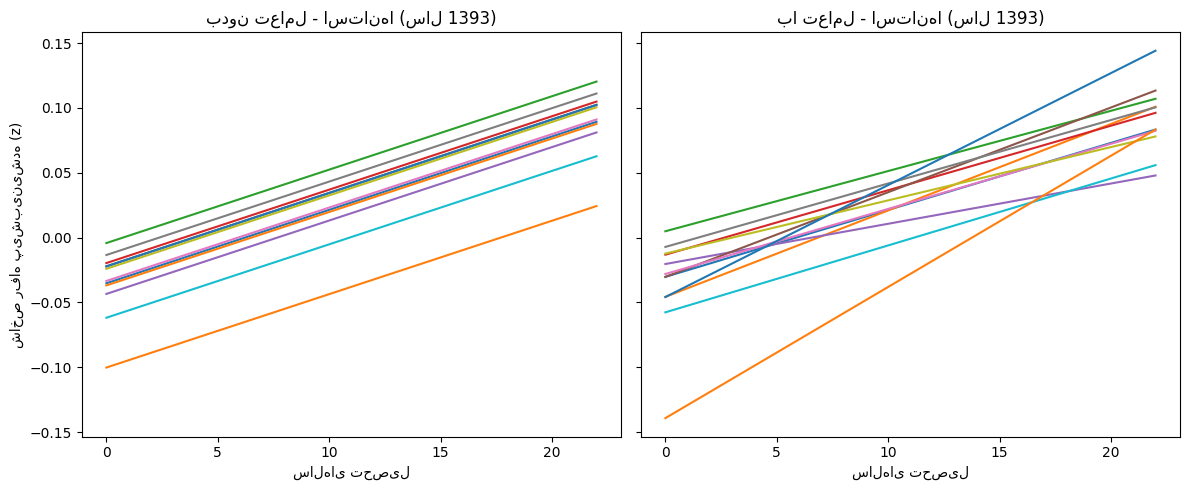

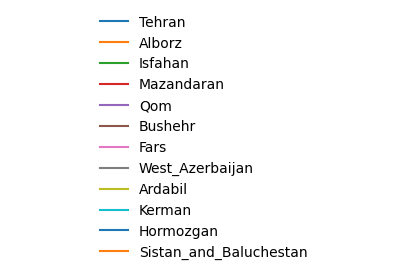


شیب اثر تحصیلات بر PPI (برآورد تعاملی) - سال 1393
Sistan_and_Baluchestan    0.010112
Hormozgan                 0.008632
Alborz                    0.006662
Bushehr                   0.006530
Tehran                    0.005163
Kerman                    0.005158
Fars                      0.005019
Mazandaran                0.004971
West_Azerbaijan           0.004891
Isfahan                   0.004642
Ardabil                   0.004105
Qom                       0.003103
Name: Slope_by_Province_1393, dtype: float64

=== پردازش سال 1394 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.242
Model:                            OLS   Adj. R-squared:                  0.241
Method:                 Least Squares   F-statistic:                     306.1
Date:                Wed, 17 Sep 2025   Prob (F-statistic):               0.00
Time:            

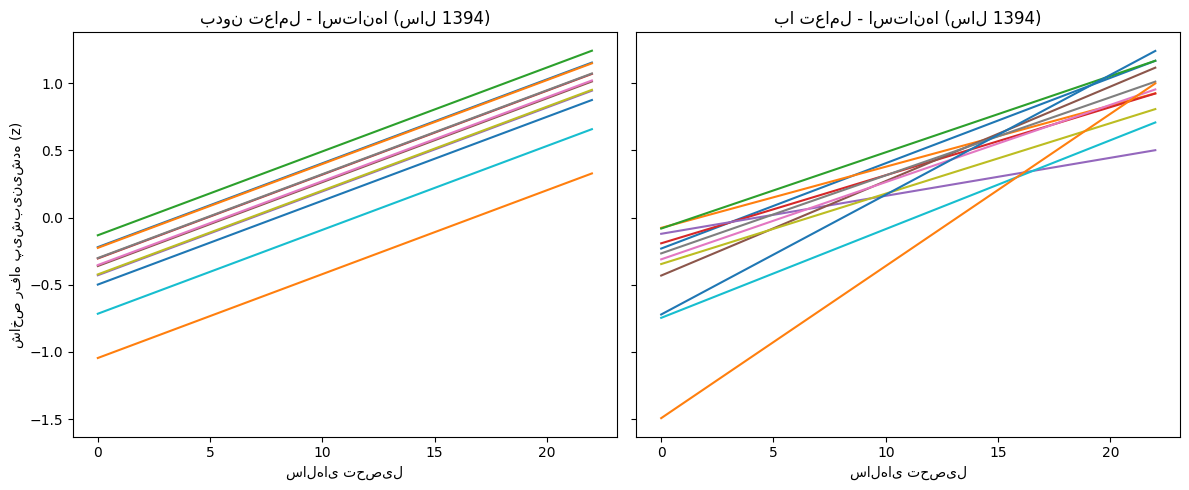

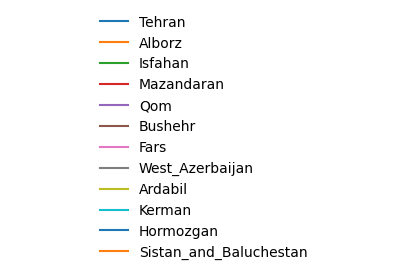


شیب اثر تحصیلات بر PPI (برآورد تعاملی) - سال 1394
Sistan_and_Baluchestan    0.113236
Hormozgan                 0.089151
Bushehr                   0.070324
Kerman                    0.066092
Tehran                    0.063514
West_Azerbaijan           0.058098
Fars                      0.057476
Isfahan                   0.056765
Ardabil                   0.052414
Mazandaran                0.050673
Alborz                    0.045510
Qom                       0.028284
Name: Slope_by_Province_1394, dtype: float64

=== پردازش سال 1395 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.175
Model:                            OLS   Adj. R-squared:                  0.174
Method:                 Least Squares   F-statistic:                     203.0
Date:                Wed, 17 Sep 2025   Prob (F-statistic):               0.00
Time:            

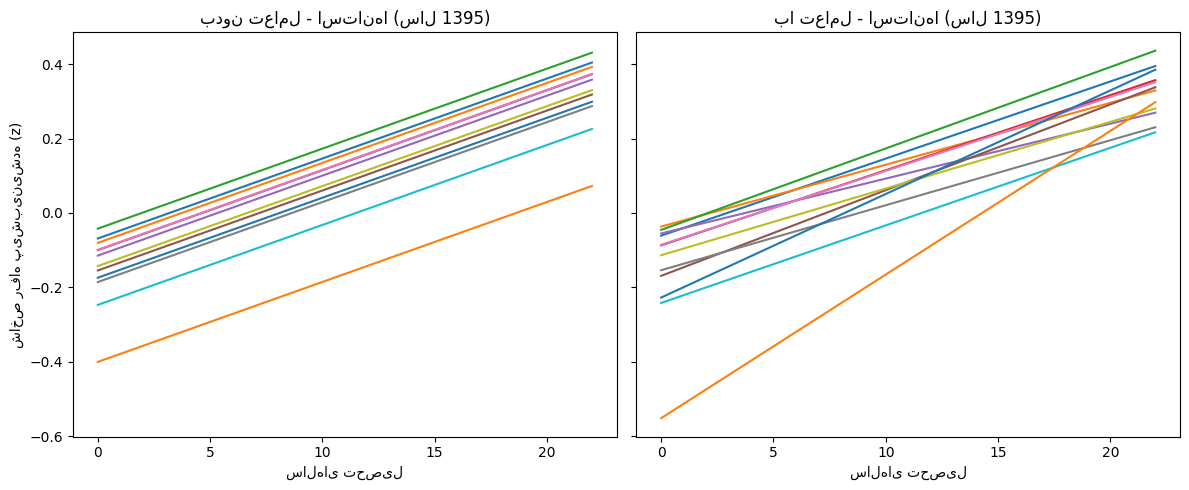

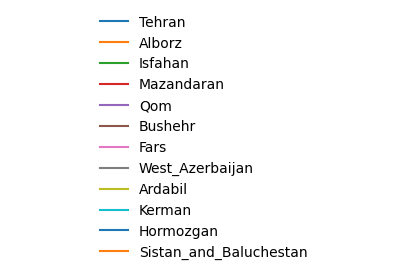


شیب اثر تحصیلات بر PPI (برآورد تعاملی) - سال 1395
Sistan_and_Baluchestan    0.038581
Hormozgan                 0.027821
Bushehr                   0.023022
Isfahan                   0.021880
Kerman                    0.020838
Tehran                    0.020711
Mazandaran                0.020171
Fars                      0.019852
Ardabil                   0.017914
West_Azerbaijan           0.017454
Alborz                    0.016622
Qom                       0.014752
Name: Slope_by_Province_1395, dtype: float64

=== پردازش سال 1396 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.265
Model:                            OLS   Adj. R-squared:                  0.264
Method:                 Least Squares   F-statistic:                     344.3
Date:                Wed, 17 Sep 2025   Prob (F-statistic):               0.00
Time:            

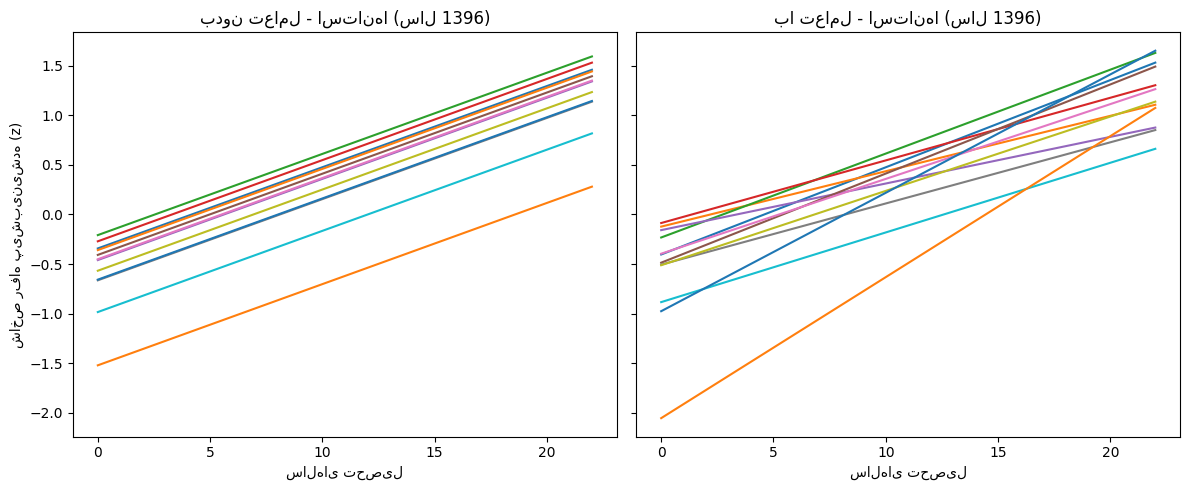

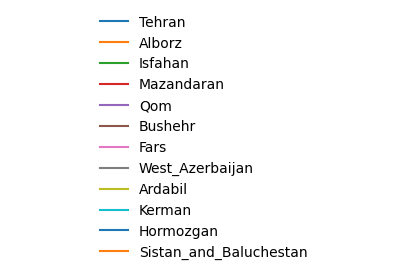


شیب اثر تحصیلات بر PPI (برآورد تعاملی) - سال 1396
Sistan_and_Baluchestan    0.142337
Hormozgan                 0.119514
Bushehr                   0.089965
Tehran                    0.088026
Isfahan                   0.084699
Fars                      0.075510
Ardabil                   0.075041
Kerman                    0.070333
Mazandaran                0.063231
West_Azerbaijan           0.061736
Alborz                    0.055916
Qom                       0.047066
Name: Slope_by_Province_1396, dtype: float64

=== پردازش سال 1397 ===
⚠ خطا در پردازش سال 1397: File is not a zip file

=== پردازش سال 1398 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.003
Model:                            OLS   Adj. R-squared:                  0.002
Method:                 Least Squares   F-statistic:                     2.891
Date:                W

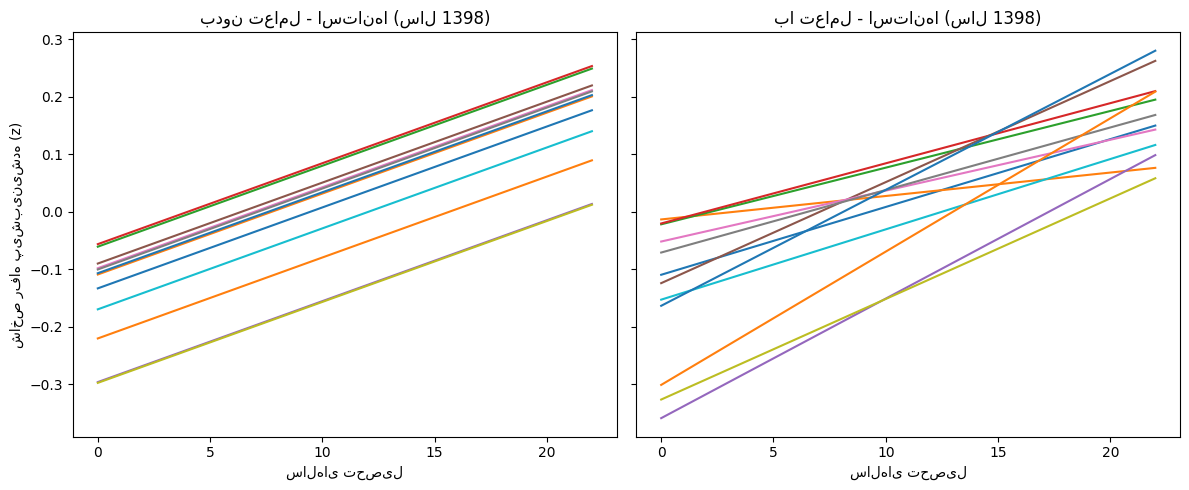

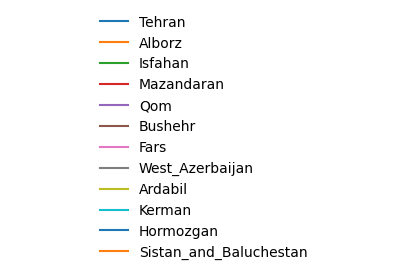


شیب اثر تحصیلات بر PPI (برآورد تعاملی) - سال 1398
Sistan_and_Baluchestan    0.023192
Qom                       0.020801
Hormozgan                 0.020173
Bushehr                   0.017579
Ardabil                   0.017500
Kerman                    0.012233
Tehran                    0.011799
West_Azerbaijan           0.010881
Mazandaran                0.010468
Isfahan                   0.009861
Fars                      0.008852
Alborz                    0.004079
Name: Slope_by_Province_1398, dtype: float64

=== پردازش سال 1399 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.173
Model:                            OLS   Adj. R-squared:                  0.173
Method:                 Least Squares   F-statistic:                     200.8
Date:                Wed, 17 Sep 2025   Prob (F-statistic):               0.00
Time:            

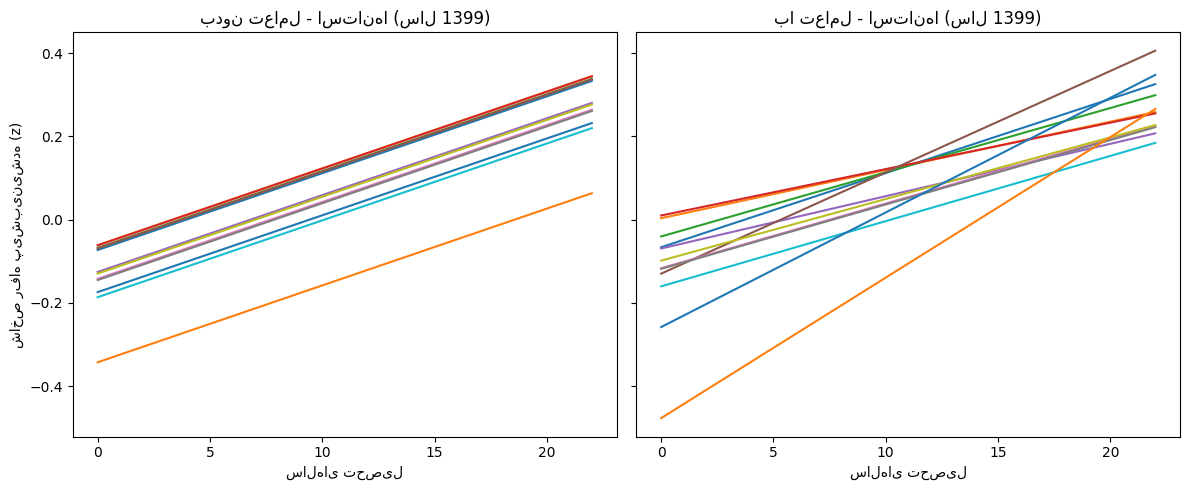

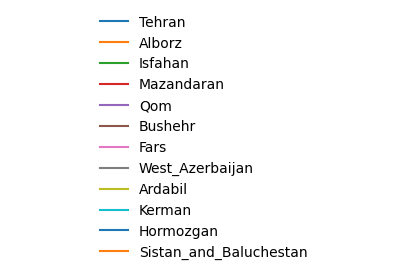


شیب اثر تحصیلات بر PPI (برآورد تعاملی) - سال 1399
Sistan_and_Baluchestan    0.033774
Hormozgan                 0.027549
Bushehr                   0.024353
Tehran                    0.017822
Kerman                    0.015676
Fars                      0.015544
West_Azerbaijan           0.015478
Isfahan                   0.015436
Ardabil                   0.014807
Qom                       0.012585
Alborz                    0.011604
Mazandaran                0.011154
Name: Slope_by_Province_1399, dtype: float64

=== پردازش سال 1400 ===

---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.263
Model:                            OLS   Adj. R-squared:                  0.262
Method:                 Least Squares   F-statistic:                     348.1
Date:                Wed, 17 Sep 2025   Prob (F-statistic):               0.00
Time:            

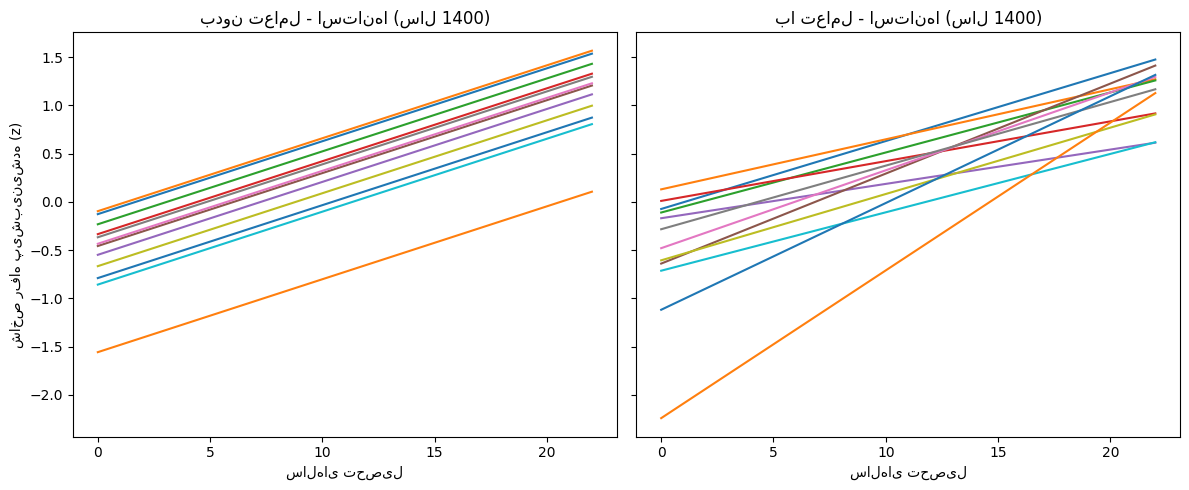

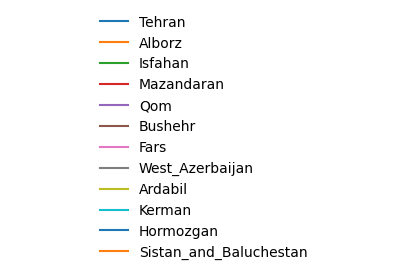


شیب اثر تحصیلات بر PPI (برآورد تعاملی) - سال 1400
Sistan_and_Baluchestan    0.153048
Hormozgan                 0.110583
Bushehr                   0.093231
Fars                      0.080668
Tehran                    0.070364
Ardabil                   0.068717
West_Azerbaijan           0.065899
Isfahan                   0.062194
Kerman                    0.060488
Alborz                    0.051843
Mazandaran                0.041199
Qom                       0.035560
Name: Slope_by_Province_1400, dtype: float64

=== پردازش سال 1401 ===


C:\Users\tadbirsabz\AppData\Local\Temp\ipykernel_30672\175096224.py:71: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  exp["Region_PriceIndex"] = exp["Region_PriceIndex"].fillna(1.0)
C:\Users\tadbirsabz\AppData\Local\Temp\ipykernel_30672\175096224.py:96: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  hh_region = hh_region.merge(reg_pindex, on="Region", how="left").fillna({"Region_PriceIndex":1.0})



---- مدل بدون تعامل (وابسته = PPI_pca_z) ----
                            OLS Regression Results                            
Dep. Variable:              PPI_pca_z   R-squared:                       0.065
Model:                            OLS   Adj. R-squared:                  0.064
Method:                 Least Squares   F-statistic:                     68.61
Date:                Wed, 17 Sep 2025   Prob (F-statistic):          1.11e-162
Time:                        20:06:45   Log-Likelihood:                -10255.
No. Observations:               11779   AIC:                         2.054e+04
Df Residuals:                   11766   BIC:                         2.063e+04
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                                            coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------

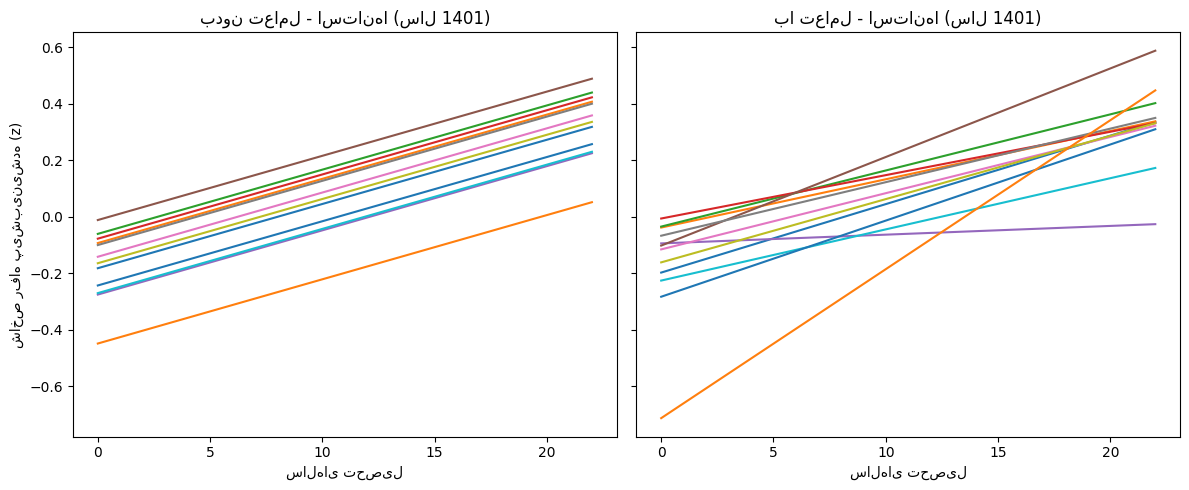

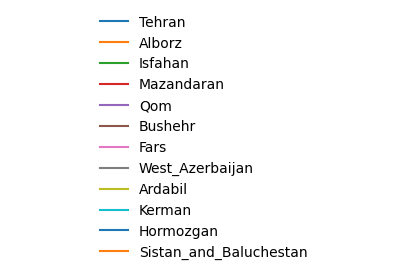


شیب اثر تحصیلات بر PPI (برآورد تعاملی) - سال 1401
Sistan_and_Baluchestan    0.052713
Bushehr                   0.031344
Hormozgan                 0.026938
Tehran                    0.024227
Ardabil                   0.022386
Fars                      0.019892
Isfahan                   0.019860
West_Azerbaijan           0.018947
Kerman                    0.018112
Alborz                    0.017081
Mazandaran                0.015349
Qom                       0.003093
Name: Slope_by_Province_1401, dtype: float64


In [ ]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

import hbsir
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# ---------------------------
# Helpers
# ---------------------------
def winsorize(s, low_q=0.01, high_q=0.99):
    lo, hi = s.quantile(low_q), s.quantile(high_q)
    return s.clip(lower=lo, upper=hi)

def safe_log_series(s, eps=1.0):
    s = pd.to_numeric(s, errors="coerce").astype("float64")
    s = s.replace([np.inf, -np.inf], np.nan)
    s = s.clip(lower=eps)
    return np.log(s)

from pandas.api.types import is_numeric_dtype
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

def cast_numeric(df: pd.DataFrame) -> pd.DataFrame:
    """هر ستونی که عددی باشد را به float64 استاندارد تبدیل می‌کند (رفع UInt8Dtype و ...)."""
    for c in df.columns:
        if is_numeric_dtype(df[c]):
            df[c] = pd.to_numeric(df[c], errors="coerce").astype("float64")
    return df

def build_ppi_for_year(year):
    """PPI (PCA) را برای هر خانوار در سالِ ورودی می‌سازد و برمی‌گرداند."""
    hbsir.setup(years=[year])

    # --- Load
    exp = hbsir.load_table("Expenditures", years=[year])
    exp = hbsir.add_attribute(exp, name="Province")
    exp = hbsir.add_attribute(exp, name="County")
    exp = hbsir.add_attribute(exp, name="Urban_Rural")

    inc = hbsir.load_table("employment_income", years=[year])
    mem = hbsir.load_table("members_properties", years=[year])

    # --- Cast numeric to float64 (fix UInt8Dtype)
    exp = cast_numeric(exp)
    inc = cast_numeric(inc)
    mem = cast_numeric(mem)

    hh_key = "ID"

    # --- Category flags
    is_food = (exp.get("Table_Name", pd.Series(index=exp.index, dtype=object)) == "food")
    is_housing = (exp.get("Table_Name", pd.Series(index=exp.index, dtype=object)) == "home")

    # --- Regional price index (Province × Urban_Rural)
    price_df = exp.dropna(subset=["Price", "Commodity_Code"]).copy()
    nat_price = price_df.groupby("Commodity_Code")["Price"].median().rename("Nat_MedPrice")
    price_df = price_df.merge(nat_price, on="Commodity_Code", how="left")
    price_df = price_df[(price_df["Nat_MedPrice"] > 0) & (price_df["Price"] > 0)]
    price_df["RelPrice"] = price_df["Price"] / price_df["Nat_MedPrice"]
    price_df["Region"] = price_df["Province"].astype(str) + " | " + price_df["Urban_Rural"].astype(str)
    reg_item_rel = (price_df.groupby(["Region", "Commodity_Code"])["RelPrice"].median().reset_index())
    reg_pindex = (reg_item_rel.groupby("Region")["RelPrice"].median()
                  .rename("Region_PriceIndex").reset_index())

    exp["Region"] = exp["Province"].astype(str) + " | " + exp["Urban_Rural"].astype(str)
    exp = exp.merge(reg_pindex, on="Region", how="left")
    exp["Region_PriceIndex"] = exp["Region_PriceIndex"].fillna(1.0)

    # --- Real expenditures
    exp["Use_Exp"] = exp["Net_Expenditure"].fillna(exp["Gross_Expenditure"])
    exp["Real_Exp"] = exp["Use_Exp"] / exp["Region_PriceIndex"]

    hh_exp = exp.groupby(hh_key, as_index=False).agg(
        total_exp=("Use_Exp", "sum"),
        real_total_exp=("Real_Exp", "sum"),
        food_exp=("Use_Exp", lambda s: s[is_food.loc[s.index]].sum() if len(s) else 0.0),
        housing_exp=("Use_Exp", lambda s: s[is_housing.loc[s.index]].sum() if len(s) else 0.0),
    )
    hh_exp["food_share"]   = np.where(hh_exp["total_exp"]>0, hh_exp["food_exp"]/hh_exp["total_exp"], np.nan)
    hh_exp["rent_burden"]  = np.where(hh_exp["total_exp"]>0, hh_exp["housing_exp"]/hh_exp["total_exp"], np.nan)

    # --- Real income (sum all numeric cols safely)
    num_cols = [c for c in inc.columns if c not in [hh_key, "Year"] and is_numeric_dtype(inc[c])]
    if len(num_cols) == 0:
        hh_inc = inc[[hh_key]].drop_duplicates().copy()
        hh_inc["income_total"] = np.nan
    else:
        hh_inc = inc.groupby(hh_key, as_index=False)[num_cols].sum()
        hh_inc["income_total"] = hh_inc[num_cols].sum(axis=1)

    hh_region = exp[[hh_key, "Region"]].drop_duplicates()
    hh_region = hh_region.merge(reg_pindex, on="Region", how="left").fillna({"Region_PriceIndex":1.0})
    hh_inc = hh_inc.merge(hh_region[[hh_key, "Region_PriceIndex"]], on=hh_key, how="left")
    hh_inc["Region_PriceIndex"] = hh_inc["Region_PriceIndex"].fillna(1.0)
    hh_inc["real_income"] = hh_inc["income_total"] / hh_inc["Region_PriceIndex"]

    # --- Household size & equivalence
    size = mem.groupby(hh_key).size().rename("hh_size").reset_index()
    if "Age" in mem.columns:
        tmp = mem[[hh_key, "Age"]].copy()
        tmp["is_child"] = (pd.to_numeric(tmp["Age"], errors="coerce") < 14).astype("int")
        children = tmp.groupby(hh_key)["is_child"].sum().rename("n_children").reset_index()
        demo = size.merge(children, on=hh_key, how="left").fillna({"n_children":0})
        demo["n_adults"] = (demo["hh_size"] - demo["n_children"]).clip(lower=0)
        demo["eq_size"]  = 1 + 0.5*np.maximum(demo["n_adults"]-1, 0) + 0.3*demo["n_children"]
        demo.loc[demo["eq_size"]<=0, "eq_size"] = demo["hh_size"].replace(0,1)
    else:
        demo = size.copy()
        demo["eq_size"] = np.sqrt(np.maximum(demo["hh_size"], 1))

    # --- Merge & features
    df = hh_exp.merge(hh_inc[[hh_key, "real_income"]], on=hh_key, how="left")
    df = df.merge(demo[[hh_key, "hh_size", "eq_size"]], on=hh_key, how="left")

    df["real_exp_pc"] = df["real_total_exp"] / df["eq_size"]
    df["real_inc_pc"] = df["real_income"]    / df["eq_size"]

    # پایداری
    df["real_exp_pc"] = winsorize(pd.to_numeric(df["real_exp_pc"], errors="coerce"))
    df["real_inc_pc"] = winsorize(pd.to_numeric(df["real_inc_pc"], errors="coerce"))

    df["log_real_exp_pc"] = safe_log_series(df["real_exp_pc"], eps=1.0)
    df["log_real_inc_pc"] = safe_log_series(df["real_inc_pc"], eps=1.0)

    df["one_minus_food"] = 1 - pd.to_numeric(df["food_share"],  errors="coerce")
    df["one_minus_rent"] = 1 - pd.to_numeric(df["rent_burden"], errors="coerce")

    feature_cols = ["log_real_exp_pc", "log_real_inc_pc", "one_minus_food", "one_minus_rent"]
    X = df[feature_cols].replace([np.inf, -np.inf], np.nan).fillna(df[feature_cols].median())

    scaler = StandardScaler()
    X_std = scaler.fit_transform(X)

    pca = PCA(n_components=1, random_state=42)
    df["PPI_pca"]   = pca.fit_transform(X_std).ravel()
    df["PPI_pca_z"] = (df["PPI_pca"] - df["PPI_pca"].mean()) / df["PPI_pca"].std(ddof=0)
    df["PPI_score"] = 100 + 15*df["PPI_pca_z"]

    geo = exp[[hh_key, "Urban_Rural", "Province"]].drop_duplicates()
    df = df.merge(geo, on=hh_key, how="left")

    return df[[hh_key, "PPI_pca_z", "PPI_score", "Urban_Rural", "Province"]].drop_duplicates()



# ---------------------------
# نگاشت تحصیلات → سال‌های تحصیل (Fallback اگر نداشتی)
# ---------------------------
# اگر قبلاً valid_levels و edu_map را تعریف کرده‌ای، همین‌ها نادیده گرفته می‌شوند.
try:
    valid_levels  # type: ignore
    edu_map       # type: ignore
except NameError:
    valid_levels = [
        "illiterate", "primary_incomplete", "primary", "middle",
        "highschool", "diploma", "associate", "bachelor",
        "master", "phd"
    ]
    edu_map = {
        "illiterate": 0,
        "primary_incomplete": 3,
        "primary": 5,
        "middle": 8,
        "highschool": 11,
        "diploma": 12,
        "associate": 14,
        "bachelor": 16,
        "master": 18,
        "phd": 21
    }

# ---------------------------
# Loop: سال‌ها و مدل تعاملی با PPI
# ---------------------------
for year in range(1393, 1403):
    print(f"\n=== پردازش سال {year} ===")
    try:
        hbsir.setup(method="download_cleaned",download_source="mirror",years=[year])
        # داده‌ها
        table = hbsir.load_table("Expenditures", years=[year])
        table = hbsir.add_attribute(table, name="Province")
        table = hbsir.add_attribute(table, name="County")
        table = hbsir.add_attribute(table, name="Urban_Rural")

        hhinc = hbsir.load_table("employment_income", years=[year])
        members = hbsir.load_table("members_properties", years=[year])

        # ساخت PPI
        ppi_df = build_ppi_for_year(year)  # ID, PPI_pca_z, PPI_score, Urban_Rural, Province

        # فیلتر سرپرست + نگاشت تحصیلات
        df = members[(members["Member_Number"] == 1)].copy()
        # اگر Education_Level متنی‌ست:
        if "Education_Level" in df.columns:
            df = df[df["Education_Level"].isin(valid_levels)].copy()
            df["Years_Edu"] = df["Education_Level"].map(edu_map).astype(float)
        else:
            # اگر ستون سال تحصیل مستقیم داری:
            if "Years_Edu" not in df.columns:
                raise ValueError("ستون Education_Level یا Years_Edu در members_properties پیدا نشد.")
            df["Years_Edu"] = pd.to_numeric(df["Years_Edu"], errors="coerce")

        # الصاق Urban_Rural و PPI از ppi_df
        df = df.merge(ppi_df, on="ID", how="left")

        # سلامت داده
        df = df.dropna(subset=["Years_Edu", "PPI_pca_z", "Urban_Rural"])
        df["Urban"] = df["Urban_Rural"].apply(lambda x: 1 if str(x).lower() == "urban" else 0)

               # ---------------- مدل‌ها و نمودار بر اساس استان ----------------
        # استان‌های منتخب برای رسم (اگر موجود نبودند، از استان‌های موجود پُر می‌کنیم)
        pref_provinces = [
            "Tehran","Alborz","Isfahan","Mazandaran","Qom",
            "Bushehr","Fars","West_Azerbaijan","Ardabil",
            "Kerman","Hormozgan","Sistan_and_Baluchestan"]

        all_provs = df["Province"].dropna().unique().tolist()
        sel_provinces = [p for p in pref_provinces if p in all_provs]
        if len(sel_provinces) < 4:
            # پُرکردن تا حداقل 4 استان
            extra = [p for p in all_provs if p not in sel_provinces]
            sel_provinces.extend(extra[:max(0, 4 - len(sel_provinces))])

        # فقط ردیف‌های استان‌های منتخب
        dfp = df[df["Province"].isin(sel_provinces)].copy()
        if dfp.empty:
            raise ValueError("هیچ رکوردی برای استان‌های انتخابی در این سال وجود ندارد.")

        # مدل بدون تعامل: شیب ثابت برای همه استان‌ها + عرض از مبدأ متفاوت
        model_no_inter = smf.ols("PPI_pca_z ~ Years_Edu + C(Province)", data=dfp).fit()
        # مدل با تعامل: شیب مجزا برای هر استان
        model_inter   = smf.ols("PPI_pca_z ~ Years_Edu * C(Province)", data=dfp).fit()

        print("\n---- مدل بدون تعامل (وابسته = PPI_pca_z) ----")
        print(model_no_inter.summary())

        print("\n---- مدل با تعامل (وابسته = PPI_pca_z) ----")
        print(model_inter.summary())

        # ---------------- گرید پیش‌بینی و رسم ----------------
        years_range = np.linspace(dfp["Years_Edu"].min(), dfp["Years_Edu"].max(), 100)
        plot_df = pd.DataFrame({
            "Years_Edu": np.tile(years_range, len(sel_provinces)),
            "Province":  np.repeat(sel_provinces, len(years_range))
        })
        plot_df["pred_no_inter"] = model_no_inter.predict(plot_df)
        plot_df["pred_inter"]    = model_inter.predict(plot_df)

        fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

        # بدون legend روی نمودار (برای شلوغ نشدن)
        for p in sel_provinces:
            sub = plot_df[plot_df["Province"] == p]
            axes[0].plot(sub["Years_Edu"], sub["pred_no_inter"], label=p)
            axes[1].plot(sub["Years_Edu"], sub["pred_inter"],    label=p)
            # اسم استان را کنار انتهای خطِ پنل تعامل بنویس (خواناتر از legend)
            

        axes[0].set_title(f"بدون تعامل - استان‌ها (سال {year})")
        axes[0].set_xlabel("سال‌های تحصیل")
        axes[0].set_ylabel("شاخص رفاه پیش‌بینی‌شده (z)")

        axes[1].set_title(f"با تعامل - استان‌ها (سال {year})")
        axes[1].set_xlabel("سال‌های تحصیل")

        handles, labels = axes[1].get_legend_handles_labels()
        plt.tight_layout()
        plt.show()

        # ساخت legend در یک شکل جدا
        fig_leg = plt.figure(figsize=(5, max(2, 0.25*len(labels))))
        fig_leg.legend(handles, labels, loc="center", ncol=1, frameon=False)
        plt.axis("off")
        plt.show()


        # شیب هر استان در مدلِ تعاملی (کمک به تفسیر)
        base_slope = model_inter.params.get("Years_Edu", np.nan)
        slopes = {}
        for p in sel_provinces:
            term = f"Years_Edu:C(Province)[T.{p}]"
            slopes[p] = base_slope + model_inter.params.get(term, 0.0)
        slopes = pd.Series(slopes, name=f"Slope_by_Province_{year}").sort_values(ascending=False)
        print("\nشیب اثر تحصیلات بر PPI (برآورد تعاملی) - سال", year)
        print(slopes)


    except Exception as e:
        print(f"⚠ خطا در پردازش سال {year}: {e}")
        continue


## Province interactions: income



=== پردازش سال 1393 ===

---- مدل بدون تعامل (وابسته = درآمد سرپرست) ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.220
Model:                                  OLS   Adj. R-squared:                  0.219
Method:                       Least Squares   F-statistic:                     141.2
Date:                      Wed, 17 Sep 2025   Prob (F-statistic):          7.81e-313
Time:                              22:34:26   Log-Likelihood:            -1.1636e+05
No. Observations:                      6016   AIC:                         2.327e+05
Df Residuals:                          6003   BIC:                         2.328e+05
Df Model:                                12                                         
Covariance Type:                  nonrobust                                         
                                            coef    std err          t     

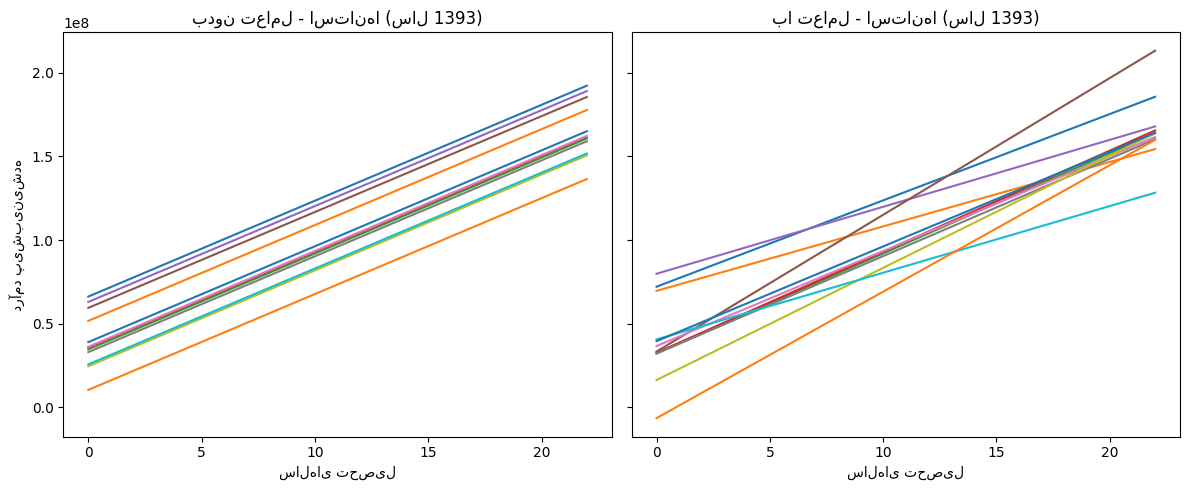

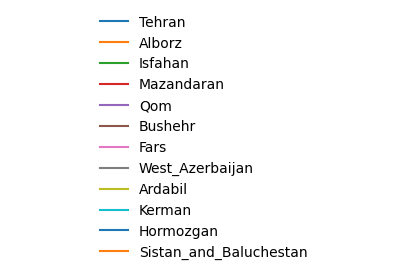


=== پردازش سال 1394 ===

---- مدل بدون تعامل (وابسته = درآمد سرپرست) ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.271
Model:                                  OLS   Adj. R-squared:                  0.269
Method:                       Least Squares   F-statistic:                     184.3
Date:                      Wed, 17 Sep 2025   Prob (F-statistic):               0.00
Time:                              22:34:52   Log-Likelihood:            -1.1558e+05
No. Observations:                      5973   AIC:                         2.312e+05
Df Residuals:                          5960   BIC:                         2.313e+05
Df Model:                                12                                         
Covariance Type:                  nonrobust                                         
                                            coef    std err          t     

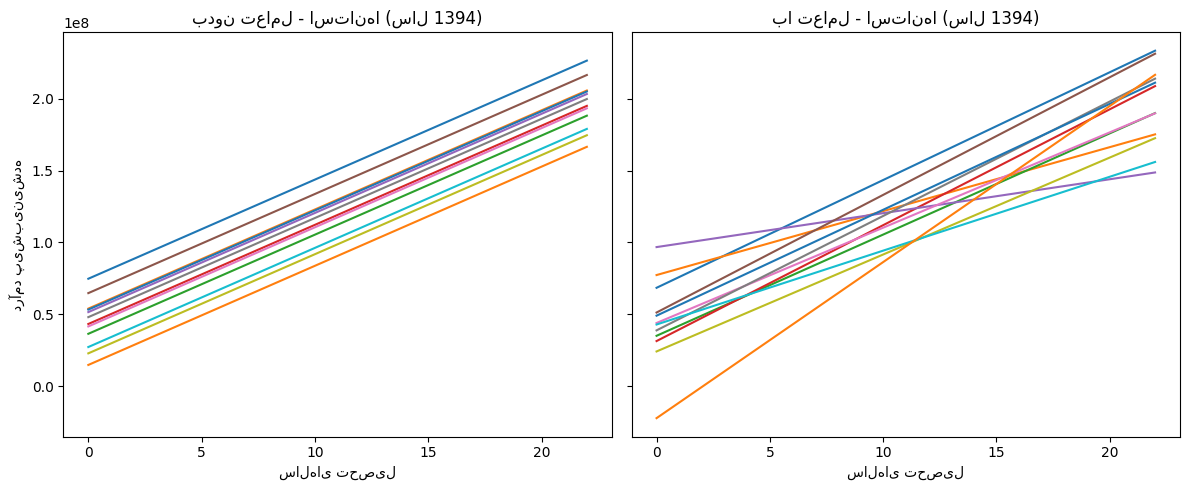

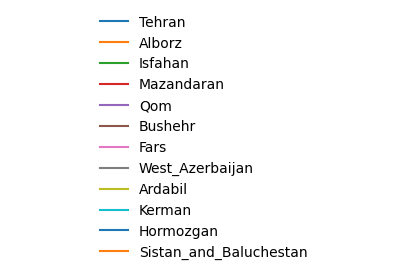


=== پردازش سال 1395 ===

---- مدل بدون تعامل (وابسته = درآمد سرپرست) ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.281
Model:                                  OLS   Adj. R-squared:                  0.280
Method:                       Least Squares   F-statistic:                     192.9
Date:                      Wed, 17 Sep 2025   Prob (F-statistic):               0.00
Time:                              22:35:19   Log-Likelihood:            -1.1605e+05
No. Observations:                      5932   AIC:                         2.321e+05
Df Residuals:                          5919   BIC:                         2.322e+05
Df Model:                                12                                         
Covariance Type:                  nonrobust                                         
                                            coef    std err          t     

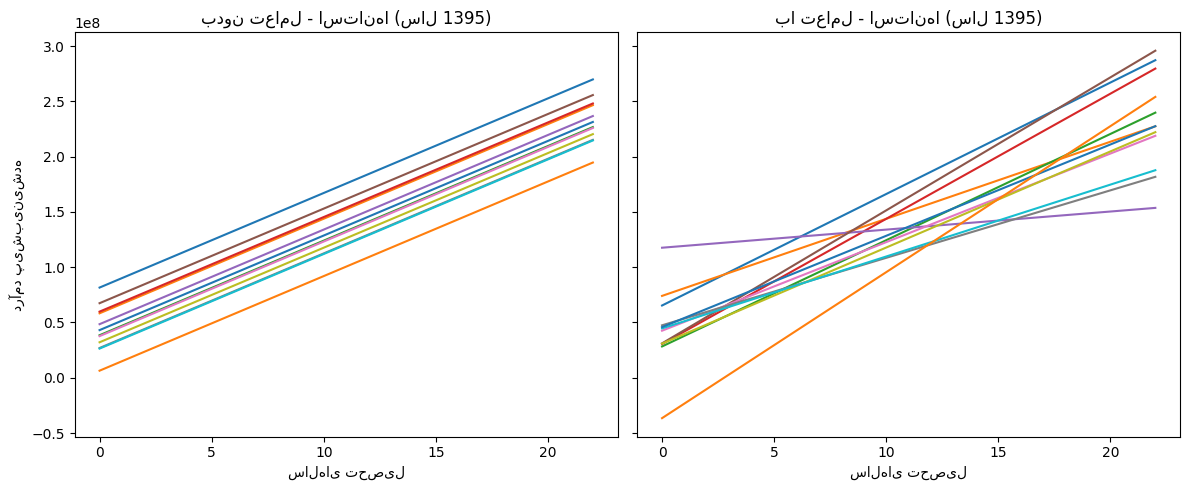

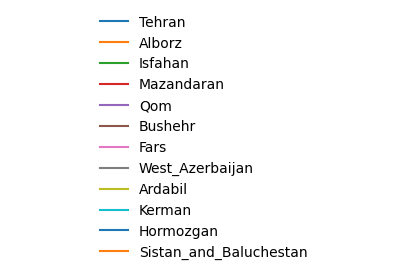


=== پردازش سال 1396 ===

---- مدل بدون تعامل (وابسته = درآمد سرپرست) ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.281
Model:                                  OLS   Adj. R-squared:                  0.279
Method:                       Least Squares   F-statistic:                     189.0
Date:                      Wed, 17 Sep 2025   Prob (F-statistic):               0.00
Time:                              22:35:39   Log-Likelihood:            -1.1480e+05
No. Observations:                      5817   AIC:                         2.296e+05
Df Residuals:                          5804   BIC:                         2.297e+05
Df Model:                                12                                         
Covariance Type:                  nonrobust                                         
                                            coef    std err          t     

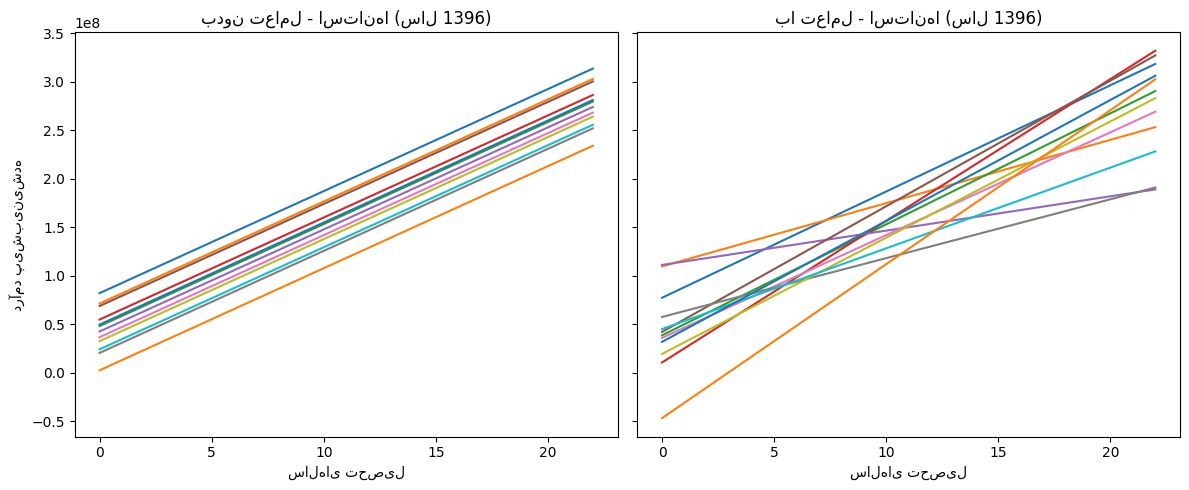

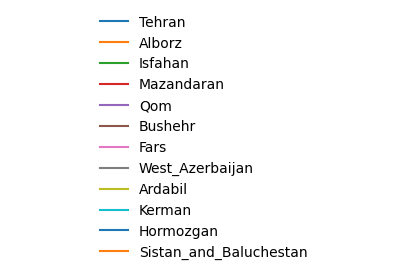


=== پردازش سال 1397 ===
⚠ خطا در پردازش سال 1397: File is not a zip file

=== پردازش سال 1398 ===

---- مدل بدون تعامل (وابسته = درآمد سرپرست) ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.265
Model:                                  OLS   Adj. R-squared:                  0.264
Method:                       Least Squares   F-statistic:                     169.0
Date:                      Wed, 17 Sep 2025   Prob (F-statistic):               0.00
Time:                              22:36:03   Log-Likelihood:            -1.1359e+05
No. Observations:                      5633   AIC:                         2.272e+05
Df Residuals:                          5620   BIC:                         2.273e+05
Df Model:                                12                                         
Covariance Type:                  nonrobust                                         
 

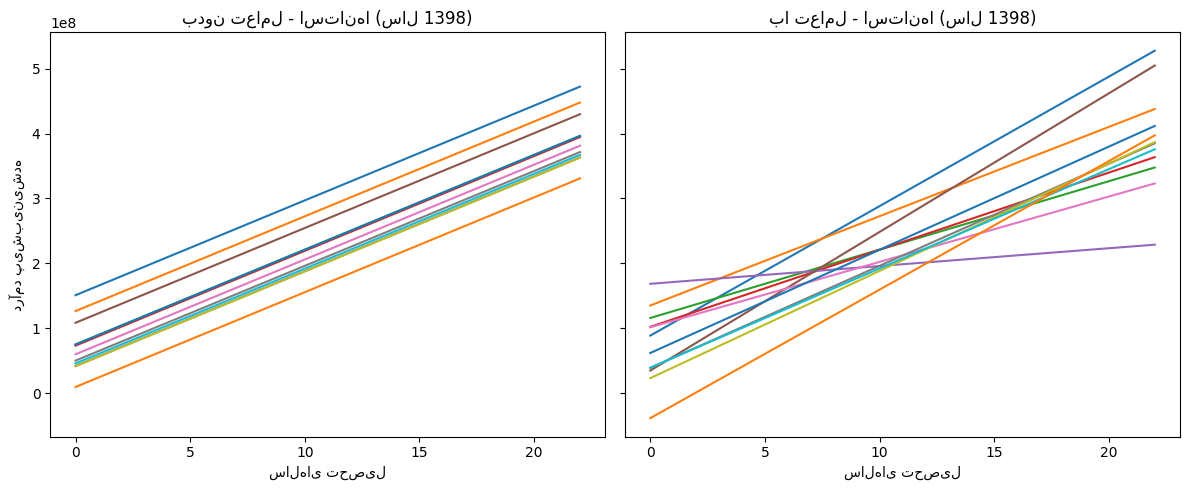

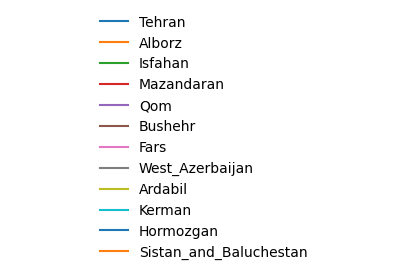


=== پردازش سال 1399 ===

---- مدل بدون تعامل (وابسته = درآمد سرپرست) ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.278
Model:                                  OLS   Adj. R-squared:                  0.277
Method:                       Least Squares   F-statistic:                     182.7
Date:                      Wed, 17 Sep 2025   Prob (F-statistic):               0.00
Time:                              22:36:25   Log-Likelihood:            -1.1616e+05
No. Observations:                      5692   AIC:                         2.324e+05
Df Residuals:                          5679   BIC:                         2.324e+05
Df Model:                                12                                         
Covariance Type:                  nonrobust                                         
                                            coef    std err          t     

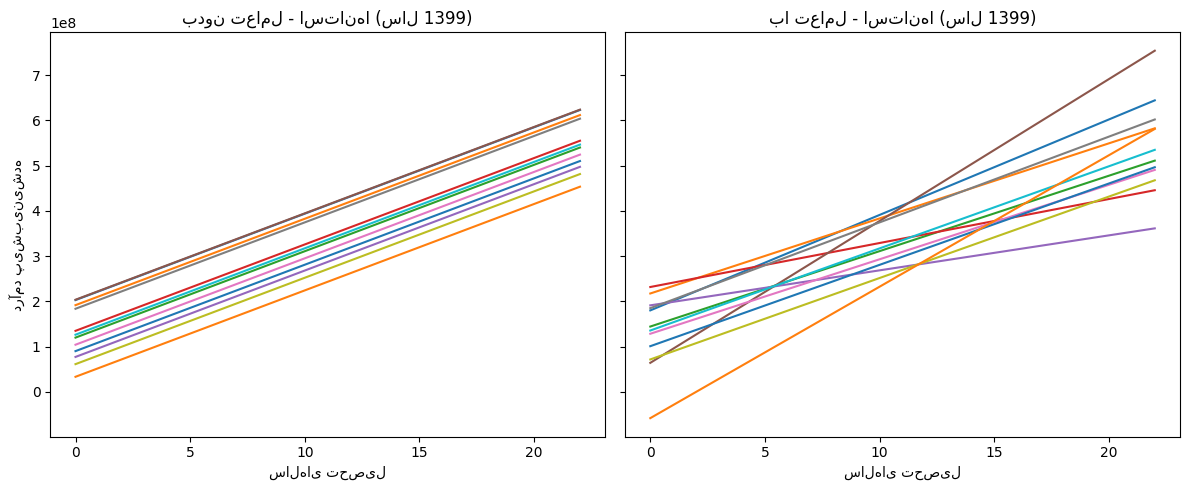

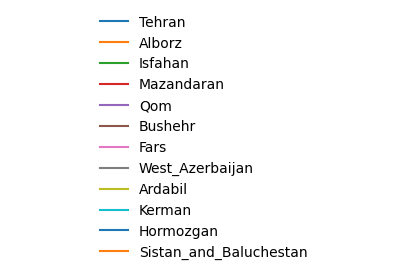


=== پردازش سال 1400 ===

---- مدل بدون تعامل (وابسته = درآمد سرپرست) ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.244
Model:                                  OLS   Adj. R-squared:                  0.242
Method:                       Least Squares   F-statistic:                     151.8
Date:                      Wed, 17 Sep 2025   Prob (F-statistic):               0.00
Time:                              22:36:48   Log-Likelihood:            -1.1779e+05
No. Observations:                      5658   AIC:                         2.356e+05
Df Residuals:                          5645   BIC:                         2.357e+05
Df Model:                                12                                         
Covariance Type:                  nonrobust                                         
                                            coef    std err          t     

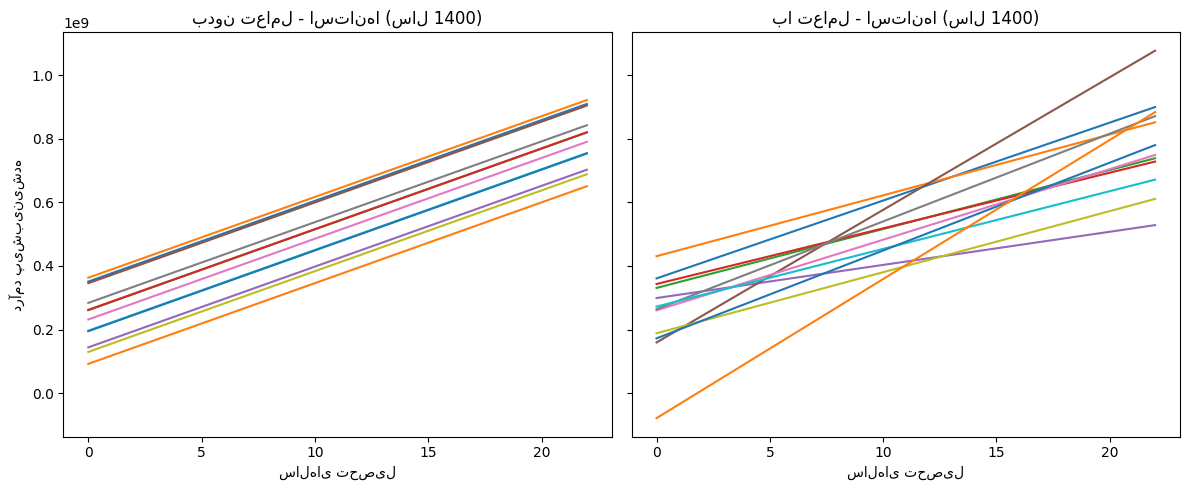

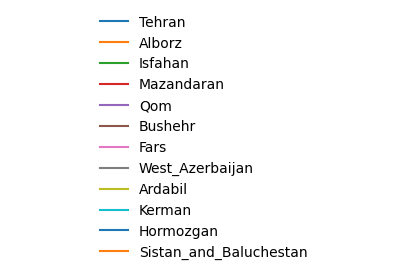


=== پردازش سال 1401 ===

---- مدل بدون تعامل (وابسته = درآمد سرپرست) ----
                               OLS Regression Results                               
Dep. Variable:     Annual_Continuous_Income   R-squared:                       0.209
Model:                                  OLS   Adj. R-squared:                  0.207
Method:                       Least Squares   F-statistic:                     124.9
Date:                      Wed, 17 Sep 2025   Prob (F-statistic):          9.09e-278
Time:                              22:37:08   Log-Likelihood:            -1.2081e+05
No. Observations:                      5681   AIC:                         2.416e+05
Df Residuals:                          5668   BIC:                         2.417e+05
Df Model:                                12                                         
Covariance Type:                  nonrobust                                         
                                            coef    std err          t     

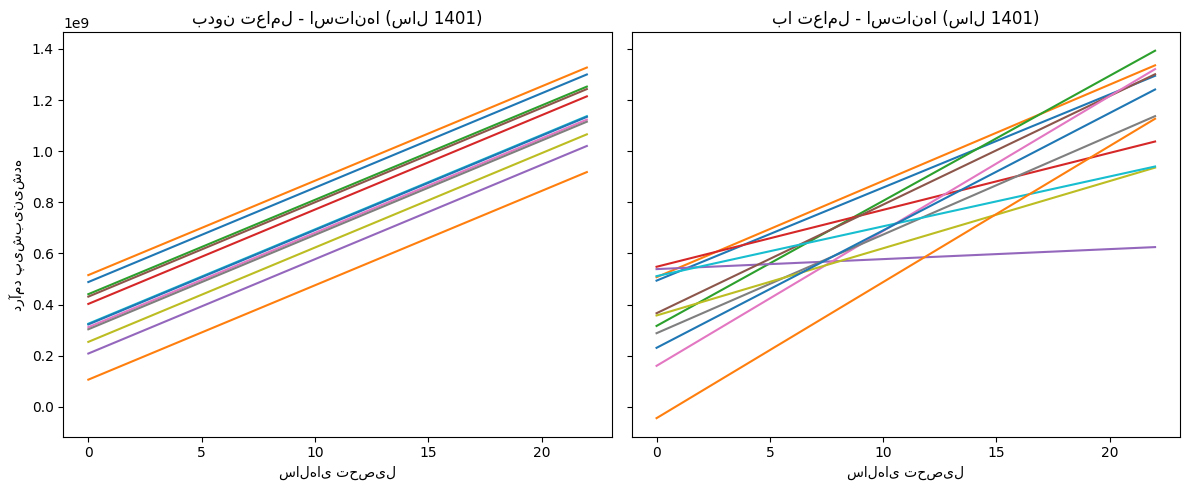

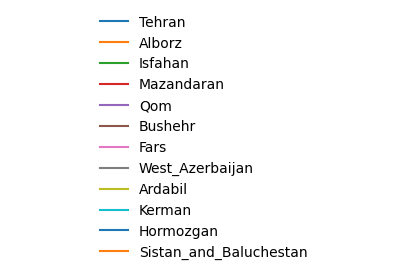

In [ ]:
for year in range(1393, 1403):
    print(f"\n=== پردازش سال {year} ===")
    try:
        # ---------- بارگذاری داده‌ها ----------
        hbsir.setup(method="download_cleaned",download_source="mirror",years=[year])
        table = hbsir.load_table("Expenditures", years=[year])
        table = hbsir.add_attribute(table, name="Province")
        table = hbsir.add_attribute(table, name="County")
        table = hbsir.add_attribute(table, name="Urban_Rural")

        hhinc = hbsir.load_table("employment_income", years=[year])
        members = hbsir.load_table("members_properties", years=[year])

        # ---------- پردازش ----------
        df = members[(members["Member_Number"] == 1) & 
                     (members["Education_Level"].isin(valid_levels))].copy()
        df["Years_Edu"] = df["Education_Level"].map(edu_map).astype(float)

        df = df.merge(
            hhinc[hhinc["Member_Number"] == 1][["ID", "Annual_Continuous_Income"]],
            on="ID", how="left"
        )

        urban_rural = table[["ID", "Urban_Rural"]].drop_duplicates()
        df = df.merge(urban_rural, on="ID", how="left")
        
        province_df = table[["ID", "Province"]].drop_duplicates()
        df = df.merge(province_df, on="ID", how="left")
        df = df.dropna(subset=["Annual_Continuous_Income", "Province"])


        df = df.dropna(subset=["Annual_Continuous_Income"])
        df["Urban"] = df["Urban_Rural"].apply(lambda x: 1 if str(x).lower() == "urban" else 0)

                # ---------- مدل بر اساس استان (بدون/با تعامل) ----------
        # چند استان نماینده برای رسم (اگر نبودند از موجودها کامل می‌کنیم)
        pref_provinces = [
            "Tehran","Alborz","Isfahan","Mazandaran","Qom",
            "Bushehr","Fars","West_Azerbaijan","Ardabil",
            "Kerman","Hormozgan","Sistan_and_Baluchestan"]
        all_provs = df["Province"].dropna().unique().tolist()
        sel_provinces = [p for p in pref_provinces if p in all_provs]
        if len(sel_provinces) < 4:
            extra = [p for p in all_provs if p not in sel_provinces]
            sel_provinces.extend(extra[:max(0, 4 - len(sel_provinces))])

        dfp = df[df["Province"].isin(sel_provinces)].copy()
        if dfp.empty:
            raise ValueError("هیچ رکوردی برای استان‌های انتخابی در این سال وجود ندارد.")

        # مدل‌ها: شیب یکسان بین استان‌ها (بدون تعامل) vs شیب متفاوت به‌ازای هر استان (با تعامل)
        model_no_inter = smf.ols("Annual_Continuous_Income ~ Years_Edu + C(Province)", data=dfp).fit()
        model_inter    = smf.ols("Annual_Continuous_Income ~ Years_Edu * C(Province)", data=dfp).fit()

        print("\n---- مدل بدون تعامل (وابسته = درآمد سرپرست) ----")
        print(model_no_inter.summary())

        print("\n---- مدل با تعامل (وابسته = درآمد سرپرست) ----")
        print(model_inter.summary())

        # ---------- نمودار ----------
        years_range = np.linspace(dfp["Years_Edu"].min(), dfp["Years_Edu"].max(), 100)
        plot_df = pd.DataFrame({
            "Years_Edu": np.tile(years_range, len(sel_provinces)),
            "Province":  np.repeat(sel_provinces, len(years_range))
        })
        plot_df["pred_no_inter"] = model_no_inter.predict(plot_df)
        plot_df["pred_inter"]    = model_inter.predict(plot_df)

        fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

        # روی خود نمودار legend نمی‌گذاریم؛ فقط label می‌دهیم تا بعداً legend جدا بسازیم
        for p in sel_provinces:
            sub = plot_df[plot_df["Province"] == p]
            axes[0].plot(sub["Years_Edu"], sub["pred_no_inter"], label=p)
            axes[1].plot(sub["Years_Edu"], sub["pred_inter"],    label=p)

        axes[0].set_title(f"بدون تعامل - استان‌ها (سال {year})")
        axes[0].set_xlabel("سال‌های تحصیل")
        axes[0].set_ylabel("درآمد پیش‌بینی‌شده")

        axes[1].set_title(f"با تعامل - استان‌ها (سال {year})")
        axes[1].set_xlabel("سال‌های تحصیل")

        # هندل/برچسب‌ها برای ساخت legend جدا
        handles, labels = axes[1].get_legend_handles_labels()

        plt.tight_layout()
        plt.show()

        # شکل جداگانه فقط برای legend
        fig_leg = plt.figure(figsize=(5, max(2, 0.25*len(labels))))
        fig_leg.legend(handles, labels, loc="center", ncol=1, frameon=False)
        plt.axis("off")
        plt.show()


    except Exception as e:
        print(f"⚠ خطا در پردازش سال {year}: {e}")
        continue
